# Meiyao_Zhou_34683720


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Task 1 — RNN Recipe Generation from Scratch

## T1.1 Data Preprocessing

In [ ]:
import pandas as pd
import json
import re
from collections import Counter

import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [ ]:
# ------------ 1. Load data ------------
base_path = "/content/drive/MyDrive/FIT5217/data/"

train_df = pd.read_csv(base_path + "train.csv")
dev_df = pd.read_csv(base_path + "dev.csv")
test_df = pd.read_csv(base_path + "test.csv")

In [ ]:
# ---------- 2. Parse JSON ----------
train_df['Ingredients'] = train_df['Ingredients'].apply(json.loads)
train_df['Recipe'] = train_df['Recipe'].apply(json.loads)

dev_df['Ingredients'] = dev_df['Ingredients'].apply(json.loads)
dev_df['Recipe'] = dev_df['Recipe'].apply(json.loads)

test_df['Ingredients'] = test_df['Ingredients'].apply(json.loads)
test_df['Recipe'] = test_df['Recipe'].apply(json.loads)

In [ ]:
# ---------- 3. Tokenization ----------
"""
Using the NLTK word tokenizer provides linguistically informed token boundaries while preserving
important patterns such as fractional quantities (e.g., "1/2") commonly found in cooking instructions.
"""

def tokenize(text_list):
    tokens = []
    for sentence in text_list:
        tokens.extend(word_tokenize(sentence.lower()))
    return tokens

train_df['ing_tokens'] = train_df['Ingredients'].apply(tokenize)
train_df['rec_tokens'] = train_df['Recipe'].apply(tokenize)

dev_df['ing_tokens'] = dev_df['Ingredients'].apply(tokenize)
dev_df['rec_tokens'] = dev_df['Recipe'].apply(tokenize)

test_df['ing_tokens'] = test_df['Ingredients'].apply(tokenize)
test_df['rec_tokens'] = test_df['Recipe'].apply(tokenize)

In [ ]:
# ---------- 4. Build vocab (train split only) ----------
token_counts = Counter()
for col in ['ing_tokens', 'rec_tokens']:
    for tokens in train_df[col]:
        token_counts.update(tokens)

threshold = 5
vocab = [t for t, c in token_counts.items() if c >= threshold]

**Justification**

I selected a frequency threshold of 5 to balance model vocabulary coverage with computational efficiency. Despite filtering tokens appearing fewer than 5 times, the OOV rate on the development split remains exceptionally low at 0.19%, ensuring the model retains semantic understanding of core culinary terms. This threshold optimizes the embedding layer size for the available 15GB VRAM while removing potential noise from spelling errors or rare brand names found in the 162,900 training rows.

In [ ]:
# ---------- 5. Special tokens ----------
special_tokens = ["<PAD>", "<UNK>", "<SOS>", "<EOS>"]
vocab = special_tokens + vocab

word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}

In [ ]:
# ---------- 6. Convert to IDs ----------
def tokens_to_ids(tokens):
    return [word2idx.get(t, word2idx["<UNK>"]) for t in tokens] # low-frequency word will be replaced with <unk>

def process_seq(tokens):
    tokens = ["<SOS>"] + tokens + ["<EOS>"]
    return tokens_to_ids(tokens)

train_df['ing_ids'] = train_df['ing_tokens'].apply(process_seq)
train_df['rec_ids'] = train_df['rec_tokens'].apply(process_seq)

dev_df['ing_ids'] = dev_df['ing_tokens'].apply(process_seq)
dev_df['rec_ids'] = dev_df['rec_tokens'].apply(process_seq)

test_df['ing_ids'] = test_df['ing_tokens'].apply(process_seq)
test_df['rec_ids'] = test_df['rec_tokens'].apply(process_seq)

In [ ]:
# ---------- 7. OOV (dev split only)----------
def compute_oov_rate(df):
    total, oov = 0, 0
    for col in ['ing_tokens', 'rec_tokens']:
        for tokens in df[col]:
            for t in tokens:
                total += 1
                if t not in word2idx:
                    oov += 1
    return oov / total

oov_rate = compute_oov_rate(dev_df)

**Sanity check**

In [ ]:
# ---------- 8. Sanity check ----------
for tok in ["<PAD>", "<UNK>", "<SOS>", "<EOS>"]:
    assert tok in word2idx, f"{tok} missing from word2idx"
    idx = word2idx[tok]
    assert idx2word[idx] == tok, f"{tok} mapping mismatch in idx2word"

**Report (Vocabulary size, OOV rate, and frequency threshold)**

In [ ]:
# ---------- 9. Report ----------
print("Vocabulary size:", len(vocab))
print("Threshold:", threshold)
print("OOV rate:", round(oov_rate, 4))

Vocabulary size: 7390
Threshold: 5
OOV rate: 0.0019


In [ ]:
# ---------- 10. save processed CSV ----------
save_path = "/content/drive/MyDrive/FIT5217/processed/"

import os
os.makedirs(save_path, exist_ok=True)

# list will be converted to strings
train_df.to_csv(save_path + "train_processed.csv", index=False)
dev_df.to_csv(save_path + "dev_processed.csv", index=False)
test_df.to_csv(save_path + "test_processed.csv", index=False)

print("Processed CSV saved to:", save_path)

Processed CSV saved to: /content/drive/MyDrive/FIT5217/processed/


In [ ]:
# ---------- 11. save processed pickle ----------
import pickle

# save DataFrame
train_df.to_pickle(save_path + "train.pkl")
dev_df.to_pickle(save_path + "dev.pkl")
test_df.to_pickle(save_path + "test.pkl")

# save vocab
with open(save_path + "word2idx.pkl", "wb") as f:
    pickle.dump(word2idx, f)

with open(save_path + "idx2word.pkl", "wb") as f:
    pickle.dump(idx2word, f)

print("Processed PKL saved to:", save_path)

Processed PKL saved to: /content/drive/MyDrive/FIT5217/processed/


**Preprocessing pipeline description**

First, the dataset was loaded from CSV files, and JSON-formatted fields for ingredients and recipes were parsed into Python lists.

Next, I applied tokenization using the NLTK word tokenizer, converting all text to lowercase.

A vocabulary was then constructed using only the training split to avoid data leakage. The vocabulary size is 7390. Tokens with a frequency lower than a threshold of 5 were mapped to the 'UNK' token. Special tokens 'PAD', 'UNK', 'SOS', and 'EOS' were added to support sequence modeling.

All token sequences were converted into integer ID sequences, with 'SOS' and 'EOS' appended to mark sequence boundaries. Finally, I computed the out-of-vocabulary (OOV) rate on the development set, which remained low (0.19%).

## T1.2 Baseline RNN Encoder-Decoder without Attention

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import pandas as pd
import pickle
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


**Dataloader**

In [ ]:
# ---------------------- data loading ------------------------------
save_path = "/content/drive/MyDrive/FIT5217/processed/"

train_df = pd.read_pickle(save_path + "train.pkl")
dev_df = pd.read_pickle(save_path + "dev.pkl")
test_df = pd.read_pickle(save_path + "test.pkl")

with open(save_path + "word2idx.pkl", "rb") as f1:
    word2idx = pickle.load(f1)

with open(save_path + "idx2word.pkl", "rb") as f2:
    idx2word = pickle.load(f2)

PAD_IDX = word2idx["<PAD>"]
SOS_IDX = word2idx["<SOS>"]
EOS_IDX = word2idx["<EOS>"]
VOCAB_SIZE = len(word2idx)

In [ ]:
# ---------------------- Dataset and DataLoader ------------------------
class RecipeDataset(Dataset):
    def __init__(self, df):
        self.inputs = df['ing_ids'].tolist()
        self.targets = df['rec_ids'].tolist()

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        return torch.tensor(self.inputs[idx]), torch.tensor(self.targets[idx])

def collate_fn(batch):
    inputs, targets = zip(*batch)

    inputs = nn.utils.rnn.pad_sequence(inputs, padding_value=PAD_IDX)
    targets = nn.utils.rnn.pad_sequence(targets, padding_value=PAD_IDX)

    return inputs.to(device), targets.to(device)

In [ ]:
train_loader = DataLoader(RecipeDataset(train_df), batch_size=128, shuffle=True, collate_fn=collate_fn)
dev_loader = DataLoader(RecipeDataset(dev_df), batch_size=128, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(RecipeDataset(test_df), batch_size=64, shuffle=False, collate_fn=collate_fn)

**RNN_baseline structure**

In [ ]:
# ------------------------ Encoder ----------------------------
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(emb_dim, hidden_dim)

    def forward(self, x):
        # x: [x_len, batch]
        embedded = self.embedding(x)
        outputs, hidden = self.rnn(embedded)
        # outputs: [x_len, batch, hidden_dim] (output of each time step)
        # hidden: [1, batch, hidden_dim] (compress the sentence into a vector, context vector)
        return outputs, hidden

In [ ]:
# ------------------------- Decoder ---------------------------
class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(emb_dim, hidden_dim)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, hidden):
        x = x.unsqueeze(0)  # [1, batch]
        embedded = self.embedding(x)

        output, hidden = self.rnn(embedded, hidden)
        prediction = self.fc(output.squeeze(0))
        return prediction, hidden

In [ ]:
class Seq2Seq(nn.Module):
    """
    Set the teacher forcing ratio to 0.5 to balance training efficiency and model robustness.
    With a probability of 0.5, the model uses the ground truth token as the next input, while otherwise it uses its own prediction.
    This helps reduce exposure bias and improves the model’s ability to handle its own generated outputs during inference.
    """
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, trg, teacher_forcing_ratio=0.5):
        batch_size = trg.shape[1]
        trg_len = trg.shape[0]

        outputs = torch.zeros(trg_len, batch_size, VOCAB_SIZE).to(device)  #[target_len, batch_size, vocab_size], store the logit(probability) of each predicted word

        encoder_outputs, hidden = self.encoder(src)

        input_token = trg[0]  # <SOS>

        for t in range(1, trg_len):
            output, hidden = self.decoder(input_token, hidden)
            outputs[t] = output

            teacher_force = random.random() < teacher_forcing_ratio # whether use teacher forcing is based on the probability
            top1 = output.argmax(1)


            input_token = trg[t] if teacher_force else top1

        return outputs

**Model initialization**

In [ ]:
ENC = Encoder(VOCAB_SIZE, emb_dim=128, hidden_dim=256)
DEC = Decoder(VOCAB_SIZE, emb_dim=128, hidden_dim=256)

model = Seq2Seq(ENC, DEC).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.001)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX) # excluding <PAD> position

### Training and Evaluation


**Training (including gradient clipping)**

In [ ]:
def train(model, loader, teacher_forcing_ratio):
    model.train()
    total_loss = 0

    for src, trg in loader:
        optimizer.zero_grad() # clean gradients before each new batch

        output = model(src, trg, teacher_forcing_ratio)

        output_dim = output.shape[-1]

        output = output[1:].reshape(-1, output_dim)
        trg = trg[1:].reshape(-1)

        loss = criterion(output, trg)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1) # gradient clipping

        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(loader)

**Evaluation**


In [ ]:
def evaluate(model, loader):
    model.eval()
    total_loss = 0

    with torch.no_grad():
        for src, trg in loader:
            output = model(src, trg, 0)  # no teacher forcing

            output_dim = output.shape[-1]

            output = output[1:].reshape(-1, output_dim)
            trg = trg[1:].reshape(-1)

            loss = criterion(output, trg)
            total_loss += loss.item()

    return total_loss / len(loader)

##### Train loop with early stopping

In [ ]:
train_losses = []
dev_losses = []

best_dev_loss = float('inf')
patience = 3
counter = 0

print("Train size:", len(train_df))


EPOCHS = 15

for epoch in range(EPOCHS):

    # teacher forcing decay
    teacher_forcing_ratio = max(0.5 - epoch * 0.05, 0.1)

    train_loss = train(model, train_loader, teacher_forcing_ratio)
    dev_loss = evaluate(model, dev_loader)

    train_losses.append(train_loss)
    dev_losses.append(dev_loss)

    print(f"Epoch {epoch+1}")
    print(f"TF ratio: {teacher_forcing_ratio:.2f}")
    print(f"Train Loss: {train_loss:.3f}")
    print(f"Dev Loss: {dev_loss:.3f}")
    print("-" * 30)

    # Early stopping
    if dev_loss < best_dev_loss:
        best_dev_loss = dev_loss
        counter = 0
        torch.save(model.state_dict(), save_path + "best_model.pt")
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping triggered")
            break

Train size: 162899
Epoch 1
TF ratio: 0.50
Train Loss: 4.604
Dev Loss: 5.452
------------------------------
Epoch 2
TF ratio: 0.45
Train Loss: 4.080
Dev Loss: 5.243
------------------------------
Epoch 3
TF ratio: 0.40
Train Loss: 4.014
Dev Loss: 5.130
------------------------------
Epoch 4
TF ratio: 0.35
Train Loss: 4.047
Dev Loss: 5.118
------------------------------
Epoch 5
TF ratio: 0.30
Train Loss: 4.106
Dev Loss: 4.994
------------------------------
Epoch 6
TF ratio: 0.25
Train Loss: 4.185
Dev Loss: 4.905
------------------------------
Epoch 7
TF ratio: 0.20
Train Loss: 4.278
Dev Loss: 4.862
------------------------------
Epoch 8
TF ratio: 0.15
Train Loss: 4.376
Dev Loss: 4.829
------------------------------
Epoch 9
TF ratio: 0.10
Train Loss: 4.470
Dev Loss: 4.800
------------------------------
Epoch 10
TF ratio: 0.10
Train Loss: 4.452
Dev Loss: 4.793
------------------------------
Epoch 11
TF ratio: 0.10
Train Loss: 4.431
Dev Loss: 4.791
------------------------------
Epoch 12
TF

**Explanation**

Early stopping was implemented using a patience-based strategy. Training terminated when the development loss failed to improve for 3 consecutive epochs. This approach helps prevent unnecessary training after the model has converged while reducing the risk of overfitting.

From the loss curves, the development loss decreased steadily during the early epochs, dropping from approximately 5.45 to 4.80 by around epoch 8, indicating that the model was successfully learning meaningful patterns from the training data. After epoch 8, the development loss plateaued with only minor fluctuations, suggesting that the model had largely converged.

The training loss initially decreased rapidly but later increased slightly before stabilising. This behaviour is likely caused by the gradual reduction of the teacher forcing ratio during training. As the decoder became increasingly dependent on its own generated tokens rather than ground-truth tokens, the training task became more difficult, resulting in a temporary increase in training loss.

Although the validation loss did not increase significantly, its plateau suggests diminishing returns from further training. Therefore, the early stopping strategy was effective in preventing unnecessary additional epochs while preserving generalisation performance.


**Loss curve**


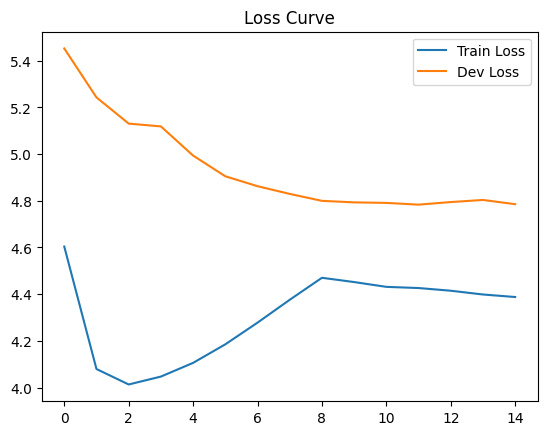

In [ ]:
plt.plot(train_losses, label="Train Loss")
plt.plot(dev_losses, label="Dev Loss")
plt.legend()
plt.title("Loss Curve")
plt.show()

### Test


In [ ]:
!pip install bert-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 5.6 MB/s eta 0:00:00


In [ ]:
import torch
import pandas as pd
from eval_metrics import evaluate1

[nltk_data] Downloading package punkt to /content/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /content/nltk_data...
[nltk_data] Downloading package omw-1.4 to /content/nltk_data...
[nltk_data] Downloading package punkt_tab to /content/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
# =========================================================
# 1. Load model
# =========================================================

model = Seq2Seq(ENC, DEC).to(device)

checkpoint = torch.load(
    "/content/drive/MyDrive/FIT5217/processed/best_model.pt",
    map_location=device
)

model.load_state_dict(checkpoint)

model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
# =========================================================
# 2. convert ids to words
# =========================================================

def ids_to_sentence(ids, idx2word):

    tokens = []

    for idx in ids:

        token = idx2word[idx]

        # Stop at <EOS>
        if token == "<EOS>":
            break

        # Pass special tokens
        if token not in ["<PAD>", "<SOS>"]:
            tokens.append(token)

    return " ".join(tokens)

In [ ]:
# =========================================================
# 3. Inference on test set
# =========================================================
"""
teacher foring ratio = 0
trg is needed
"""
all_preds = []
all_targets = []

with torch.no_grad():

    for src, trg in test_loader:

        src = src.to(device)
        trg = trg.to(device)

        output = model(
            src,
            trg,
            teacher_forcing_ratio=0
        )

        # output shape: [trg_len, batch_size, vocab_size]
        pred_tokens = output.argmax(dim=-1)

        # batch iteration
        for i in range(pred_tokens.shape[1]):

            pred_ids = pred_tokens[:, i].cpu().numpy()
            target_ids = trg[:, i].cpu().numpy()

            all_preds.append(pred_ids)
            all_targets.append(target_ids)

print("Inference completed!")

Inference completed!


In [ ]:
# =========================================================
# 4. Decode token ids -> text
# =========================================================

decoded_preds = [
    ids_to_sentence(ids, idx2word)
    for ids in all_preds
]

decoded_targets = [
    ids_to_sentence(ids, idx2word)
    for ids in all_targets
]

In [ ]:
# print outcomes
for i in range(3):

    print(f"\nExample {i+1}")
    print("Prediction:", decoded_preds[i])
    print("Target    :", decoded_targets[i])


Example 1
Prediction: mix cream cheese and marshmallow creme . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
Target    : whip cream cheese with mixer until smooth . blend in orange juice . add marshmallow creme . whip again until smooth . chill before serving .

Example 2
Prediction: brown ground and and . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
Target    : combine all ingredients . cook 30 minutes . serve on warm buns .

Example 3
Prediction: mix jello jello and pineapple and . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . .
Target    : drain juice from pineapple and save

In [ ]:
# =========================================================
# 5. Save predictions
# =========================================================
submission_df = pd.DataFrame({
    "Title": test_df["Title"].values,
    "Ingredients": test_df["Ingredients"].values,
    "Recipe_Gold": decoded_targets,
    "Recipe_T1_Baseline": decoded_preds
})

save_path = "/content/drive/MyDrive/FIT5217/generated_34683720.xlsx"

submission_df.to_excel(save_path, index=False)

print("Baseline predictions saved!")

Baseline predictions saved!


In [ ]:
# =========================================================
# 6. Evaluation
# =========================================================
evaluate1(decoded_targets, decoded_preds)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BLEU-4:    0.0107
METEOR:    0.0997
BERTScore: 0.7484


**Interpretation of Scores:**

 The very low BLEU-4 score indicates that the generated recipes rarely matched the reference recipes at the exact 4-gram level. This is expected for open-ended text generation tasks such as recipe generation, where many valid outputs may differ significantly in wording and phrasing.

The METEOR score was higher than BLEU-4, suggesting that the model was able to capture some relevant cooking vocabulary and partial token-level overlap with the reference recipes. This indicates that the model learned common recipe patterns and action words such as cooking verbs and ingredient-related terms.

The relatively high BERTScore compared to BLEU-4 suggests that the generated recipes retained reasonable semantic similarity to the reference recipes even when exact wording differed. This implies that the baseline RNN learned the general structure and semantic style of cooking instructions.


## T1.3 RNN Encoder-Decoder with Bahdanau Attention

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import pandas as pd
import pickle
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import gc

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# ---------------------- data loading ------------------------------

save_path = "/content/drive/MyDrive/FIT5217/processed/"

train_df = pd.read_pickle(save_path + "train.pkl")
dev_df = pd.read_pickle(save_path + "dev.pkl")
test_df = pd.read_pickle(save_path + "test.pkl")

with open(save_path + "word2idx.pkl", "rb") as f1:
    word2idx = pickle.load(f1)

with open(save_path + "idx2word.pkl", "rb") as f2:
    idx2word = pickle.load(f2)

PAD_IDX = word2idx["<PAD>"]
SOS_IDX = word2idx["<SOS>"]
EOS_IDX = word2idx["<EOS>"]

VOCAB_SIZE = len(word2idx)

print("VOCAB_SIZE:", VOCAB_SIZE)

VOCAB_SIZE: 7390


In [ ]:
# ---------------------- Dataset and DataLoader ------------------------

class RecipeDataset(Dataset):

    def __init__(self, df):

        self.inputs = df['ing_ids'].tolist()
        self.targets = df['rec_ids'].tolist()

    def __len__(self):

        return len(self.inputs)

    def __getitem__(self, idx):

        return (
            torch.tensor(self.inputs[idx]),
            torch.tensor(self.targets[idx])
        )

def collate_fn(batch):

    inputs, targets = zip(*batch)

    # batch_first=True
    inputs = nn.utils.rnn.pad_sequence(
        inputs,
        batch_first=True,
        padding_value=PAD_IDX
    )

    targets = nn.utils.rnn.pad_sequence(
        targets,
        batch_first=True,
        padding_value=PAD_IDX
    )

    return inputs.to(device), targets.to(device)

In [ ]:
train_loader = DataLoader(
    RecipeDataset(train_df),
    batch_size=16,
    shuffle=True,
    collate_fn=collate_fn
)

dev_loader = DataLoader(
    RecipeDataset(dev_df),
    batch_size=16,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    RecipeDataset(test_df),
    batch_size=16,
    shuffle=False,
    collate_fn=collate_fn
)

#### RNN (with attention) model structure

In this implementation, the attention score function measures how relevant each encoder hidden state is to the current decoder hidden state.

First, the decoder hidden state and each encoder output are projected into a shared space using linear layers. These representations are combined and passed through a tanh activation function to produce an intermediate energy representation. A final linear layer converts this energy into a scalar attention score for each encoder token. Higher scores indicate that the decoder should pay more attention to that ingredient token at the current decoding step.

Next, softmax normalisation is applied to all attention scores. This converts the raw scores into attention weights that form a probability distribution summing to one. The attention weights indicate the relative importance of each encoder token.

Finally, the context vector is computed as a weighted sum of all encoder hidden states using the attention weights. This context vector provides the decoder with dynamically selected information from the input sequence, helping the model capture long-range dependencies and better align generated recipe steps with relevant ingredients.


In [ ]:
# ---------------------- Bahdanau Attention ------------------------
"""
Bahdanau attention allows the decoder to dynamically focus on different input ingredient tokens
during recipe generation instead of relying only on the encoder’s final hidden state.
"""

class BahdanauAttention(nn.Module):

    def __init__(self, hidden_dim):

        super().__init__()

        self.Wa = nn.Linear(hidden_dim, hidden_dim)
        self.Ua = nn.Linear(hidden_dim, hidden_dim)
        self.Va = nn.Linear(hidden_dim, 1)

    def forward(self, hidden, encoder_outputs):

        # hidden: [1, batch, hidden]
        # encoder_outputs: [batch, src_len, hidden]

        hidden = hidden.transpose(0, 1)

        energy = torch.tanh(
            self.Wa(hidden) + self.Ua(encoder_outputs)
        )

        scores = self.Va(energy).squeeze(2)  #[batch_size, src_len] score of each time step

        # [batch, src_len]
        attn_weights = torch.softmax(scores, dim=1)

        return attn_weights

In [ ]:
# ---------------------- Encoder ------------------------

class AttnEncoder(nn.Module):

    def __init__(self, vocab_size, emb_dim, hidden_dim):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            emb_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.GRU(
            emb_dim,
            hidden_dim,
            batch_first=True
        )

    def forward(self, x):

        # x: [batch, seq_len]

        embedded = self.embedding(x)

        # outputs: [batch, seq_len, hidden]
        # hidden: [1, batch, hidden]

        outputs, hidden = self.rnn(embedded)

        return outputs, hidden

In [ ]:
# ---------------------- Decoder ------------------------

class AttnDecoder(nn.Module):

    def __init__(self, vocab_size, emb_dim, hidden_dim, attention):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            emb_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.GRU(
            emb_dim + hidden_dim,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim * 2, vocab_size)

        self.attention = attention

    def forward(self, input_token, hidden, encoder_outputs):

        # input_token: [batch]

        input_token = input_token.unsqueeze(1)

        # embedded: [batch,1,emb]
        embedded = self.embedding(input_token)

        # attn_weights: [batch, src_len]
        attn_weights = self.attention(hidden, encoder_outputs)

        # [batch,1,src_len]
        attn_weights = attn_weights.unsqueeze(1)

        # encoder_outputs: [batch,src_len,hidden]

        # context: [batch,1,hidden]
        context = torch.bmm(attn_weights, encoder_outputs)

        # rnn_input: [batch,1,emb+hidden]
        rnn_input = torch.cat((embedded, context), dim=2)

        output, hidden = self.rnn(rnn_input, hidden)

        # output: [batch, hidden]
        output = output.squeeze(1)

        # context: [batch, hidden]
        context = context.squeeze(1)

        prediction = self.fc(
            torch.cat((output, context), dim=1)
        )

        return prediction, hidden

In [ ]:
# ---------------------- Seq2Seq ------------------------

class Attn_Seq2Seq(nn.Module):

    def __init__(self, encoder, decoder):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, trg, teacher_forcing_ratio=0.5):

        # src: [batch, src_len]
        # trg: [batch, trg_len]

        batch_size = trg.shape[0]
        trg_len = trg.shape[1]

        outputs = torch.zeros(
            batch_size,
            trg_len,
            VOCAB_SIZE,
            device=device
        )

        encoder_outputs, hidden = self.encoder(src)

        # [batch]
        input_token = trg[:, 0]

        for t in range(1, trg_len):

            output, hidden = self.decoder(
                input_token,
                hidden,
                encoder_outputs
            )

            outputs[:, t, :] = output

            teacher_force = random.random() < teacher_forcing_ratio

            top1 = output.argmax(1)

            input_token = trg[:, t] if teacher_force else top1

        return outputs


**Model initialisation**

In [ ]:
# ---------------------- Model Initialisation ------------------------

attn = BahdanauAttention(hidden_dim=256)

Attn_ENC = AttnEncoder(
    VOCAB_SIZE,
    emb_dim=128,
    hidden_dim=256
)

Attn_DEC = AttnDecoder(
    VOCAB_SIZE,
    emb_dim=128,
    hidden_dim=256,
    attention=attn
)

model_attn = Attn_Seq2Seq(
    Attn_ENC,
    Attn_DEC
).to(device)

optimizer_attn = torch.optim.Adam(
    model_attn.parameters(),
    lr=0.0005
)

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)

### Training and Evaluation

In [ ]:
def Attn_train(model, loader, teacher_forcing_ratio):

    model.train()

    total_loss = 0

    for i, (src, trg) in enumerate(loader):

        optimizer_attn.zero_grad()

        output = model(src, trg, teacher_forcing_ratio)

        output_dim = output.shape[-1]

        # output: [batch, trg_len, vocab]
        output = output[:, 1:, :].reshape(-1, output_dim)

        # trg: [batch, trg_len]
        trg = trg[:, 1:].reshape(-1)

        loss = criterion(output, trg)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1
        )

        optimizer_attn.step()

        total_loss += loss.item()

        del output, trg, loss

        if i % 100 == 0:
            torch.cuda.empty_cache()
            gc.collect()

    return total_loss / len(loader)

In [ ]:
def Attn_evaluate(model, loader):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for src, trg in loader:

            output = model(src, trg, 0)

            output_dim = output.shape[-1]

            output = output[:, 1:, :].reshape(-1, output_dim)

            trg = trg[:, 1:].reshape(-1)

            loss = criterion(output, trg)

            total_loss += loss.item()

            del output, trg, loss

    gc.collect()
    torch.cuda.empty_cache()

    return total_loss / len(loader)

In [ ]:
# ---------------------- Training Loop ------------------------

EPOCHS = 15
patience = 3

best_dev = float('inf')
counter = 0

train_losses = []
dev_losses = []

for epoch in range(EPOCHS):

    tf_ratio = max(0.5 - epoch * 0.05, 0.1)

    train_loss = Attn_train(
        model_attn,
        train_loader,
        tf_ratio
    )

    dev_loss = Attn_evaluate(
        model_attn,
        dev_loader
    )

    train_losses.append(train_loss)
    dev_losses.append(dev_loss)

    print(f"\nEpoch {epoch+1}")
    print(f"TF ratio: {tf_ratio:.2f}")
    print(f"Train Loss: {train_loss:.3f}")
    print(f"Dev Loss: {dev_loss:.3f}")

    if dev_loss < best_dev:

        best_dev = dev_loss
        counter = 0

        torch.save(
            model_attn.state_dict(),
            save_path + "attn_model.pt"
        )

        print("Model saved.")

    else:

        counter += 1

        if counter >= patience:
            print("Early stopping triggered.")
            break

    gc.collect()
    torch.cuda.empty_cache()


Epoch 1
TF ratio: 0.50
Train Loss: 4.018
Dev Loss: 5.244
Model saved.

Epoch 2
TF ratio: 0.45
Train Loss: 3.720
Dev Loss: 5.248

Epoch 3
TF ratio: 0.40
Train Loss: 3.737
Dev Loss: 5.093
Model saved.

Epoch 4
TF ratio: 0.35
Train Loss: 3.810
Dev Loss: 4.958
Model saved.

Epoch 5
TF ratio: 0.30
Train Loss: 3.889
Dev Loss: 4.933
Model saved.

Epoch 6
TF ratio: 0.25
Train Loss: 3.985
Dev Loss: 4.839
Model saved.


OutOfMemoryError: CUDA out of memory. Tried to allocate 30.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 15.81 MiB is free. Including non-PyTorch memory, this process has 14.54 GiB memory in use. Of the allocated memory 13.32 GiB is allocated by PyTorch, and 1.09 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

**Loss curve**

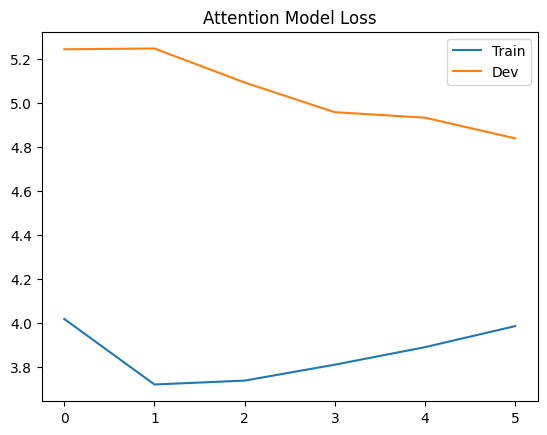

In [ ]:
plt.plot(train_losses, label="Train")
plt.plot(dev_losses, label="Dev")
plt.legend()
plt.title("Attention Model Loss")
plt.show()

### Test


In [ ]:
!pip install bert-score

In [ ]:
import torch
import pandas as pd
from eval_metrics import evaluate1

[nltk_data] Downloading package punkt to /content/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /content/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /content/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt_tab to /content/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Before testing, modify decoder and seq2seq to ensure the prediction contains attention weights

In [ ]:
# ---------------------- Decoder ------------------------

class AttnDecoder(nn.Module):

    def __init__(self, vocab_size, emb_dim, hidden_dim, attention):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            emb_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.GRU(
            emb_dim + hidden_dim,
            hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim * 2, vocab_size)

        self.attention = attention

    def forward(self, input_token, hidden, encoder_outputs):

        # input_token: [batch]

        input_token = input_token.unsqueeze(1)

        # embedded: [batch,1,emb]
        embedded = self.embedding(input_token)

        # attn_weights: [batch, src_len]
        attn_weights = self.attention(hidden, encoder_outputs)

        # [batch,1,src_len]
        attn_weights = attn_weights.unsqueeze(1)

        # encoder_outputs: [batch,src_len,hidden]

        # context: [batch,1,hidden]
        context = torch.bmm(attn_weights, encoder_outputs)

        # rnn_input: [batch,1,emb+hidden]
        rnn_input = torch.cat((embedded, context), dim=2)

        output, hidden = self.rnn(rnn_input, hidden)

        # output: [batch, hidden]
        output = output.squeeze(1)

        # context: [batch, hidden]
        context = context.squeeze(1)

        prediction = self.fc(
            torch.cat((output, context), dim=1)
        )

        return prediction, hidden, attn_weights

In [ ]:
# ---------------------- Seq2Seq ------------------------

class Attn_Seq2Seq(nn.Module):

    def __init__(self, encoder, decoder):

        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, src, trg, teacher_forcing_ratio=0.5):

        # src: [batch, src_len]
        # trg: [batch, trg_len]

        batch_size = trg.shape[0]
        trg_len = trg.shape[1]

        outputs = torch.zeros(
            batch_size,
            trg_len,
            VOCAB_SIZE,
            device=device
        )

        all_attentions = []

        encoder_outputs, hidden = self.encoder(src)

        # [batch]
        input_token = trg[:, 0]

        for t in range(1, trg_len):

            output, hidden, attn = self.decoder(
                input_token,
                hidden,
                encoder_outputs
            )

            outputs[:, t, :] = output
            all_attentions.append(attn.detach().cpu())

            teacher_force = random.random() < teacher_forcing_ratio

            top1 = output.argmax(1)

            input_token = trg[:, t] if teacher_force else top1

        return outputs, all_attentions


In [ ]:
# ---------------------- Model Initialisation ------------------------

attn = BahdanauAttention(hidden_dim=256)

Attn_ENC = AttnEncoder(
    VOCAB_SIZE,
    emb_dim=128,
    hidden_dim=256
)

Attn_DEC = AttnDecoder(
    VOCAB_SIZE,
    emb_dim=128,
    hidden_dim=256,
    attention=attn
)

model_attn = Attn_Seq2Seq(
    Attn_ENC,
    Attn_DEC
).to(device)

optimizer_attn = torch.optim.Adam(
    model_attn.parameters(),
    lr=0.0005
)

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)

In [ ]:
# =========================================================
# 1. Load model
# =========================================================

model_attn = Attn_Seq2Seq(
    Attn_ENC,
    Attn_DEC
).to(device)

checkpoint = torch.load(
    "/content/drive/MyDrive/FIT5217/processed/attn_model.pt",
    map_location=device
)

model_attn.load_state_dict(checkpoint)

model_attn.eval()

print("Attention model loaded successfully!")

Attention model loaded successfully!


In [ ]:
# =========================================================
# 2. convert ids to words
# =========================================================

def ids_to_sentence(ids, idx2word):

    tokens = []

    for idx in ids:

        token = idx2word[idx]

        # Stop at <EOS>
        if token == "<EOS>":
            break

        # Pass special tokens
        if token not in ["<PAD>", "<SOS>"]:
            tokens.append(token)

    return " ".join(tokens)

In [ ]:
# =========================================================
# 3. Inference on test set
# =========================================================
"""
teacher foring ratio = 0
trg is needed
"""
all_preds = []
all_targets = []

with torch.no_grad():

    for src, trg in test_loader:

        src = src.to(device)
        trg = trg.to(device)

        output, attentions = model_attn(
            src,
            trg,
            teacher_forcing_ratio=0
        )

        # output shape = [batch, trg_len, vocab]
        pred_tokens = output.argmax(dim=-1)

        # batch iteration
        for i in range(pred_tokens.shape[0]):

            pred_ids = pred_tokens[i].cpu().numpy()
            target_ids = trg[i].cpu().numpy()

            all_preds.append(pred_ids)
            all_targets.append(target_ids)

print("Inference completed!")

Inference completed!


In [ ]:
# =========================================================
# 4. Decode token ids -> text
# =========================================================

decoded_preds = [
    ids_to_sentence(ids, idx2word)
    for ids in all_preds
]

decoded_targets = [
    ids_to_sentence(ids, idx2word)
    for ids in all_targets
]

In [ ]:
# print outcomes
for i in range(3):

    print(f"\nExample {i+1}")
    print("Prediction:", decoded_preds[i])
    print("Target    :", decoded_targets[i])


Example 1
Prediction: mix all ingredients together . serve with fresh fruit .
Target    : whip cream cheese with mixer until smooth . blend in orange juice . add marshmallow creme . whip again until smooth . chill before serving .

Example 2
Prediction: brown ground beef and onions . add . ingredients . simmer until minutes .
Target    : combine all ingredients . cook 30 minutes . serve on warm buns .

Example 3
Prediction: mix jello and sugar and sugar . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . . top with cool whip .
Target    : drain juice from pineapple and save . prepare lemon jello as directed and pour into a 9 x 13-inch pyrex dish . allow to jell a little . add pineapple to jello and stir well . let it jell completely . mix 1 cup pineapple juice , flour and beaten eggs in saucepan over low heat for 10 minutes . cool . spoon over jello layer . then spoon whipped topping over this layer 

In [ ]:
# =========================================================
# 5. Save predictions
# =========================================================

save_path = "/content/drive/MyDrive/FIT5217/generated_34683720.xlsx"

submission_df = pd.read_excel(save_path)

submission_df["Recipe_T1_Attention"] = decoded_preds

submission_df.to_excel(save_path, index=False)

print("Attention predictions appended successfully!")

Attention predictions appended successfully!


In [ ]:
# =========================================================
# 6. Evaluation
# =========================================================
evaluate1(decoded_targets, decoded_preds)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BLEU-4:    0.0355
METEOR:    0.1623
BERTScore: 0.8032


**Interpretation of Scores:**

The attention-based RNN outperformed the baseline encoder-decoder model across all three metrics. The improvement in BLEU-4 suggests that the attention mechanism helped the decoder generate recipe instructions with better token-level alignment and more accurate phrase patterns compared to the reference recipes.

The higher METEOR score indicates improved lexical overlap and better preservation of recipe structure. This suggests that the model learned more appropriate cooking actions and ingredient-related vocabulary.

In addition, the BERTScore exceeding 0.80 demonstrates that the generated recipes achieved stronger semantic similarity to the gold recipes, even when exact wording differed.

These improvements can be attributed to the Bahdanau attention mechanism, which allows the decoder to dynamically access all encoder hidden states during generation rather than relying solely on the encoder’s final hidden state.


**Attention Heatmap**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_attention(attentions, src_tokens, trg_tokens):

    # [trg_len-1, src_len]
    attn_matrix = attentions.detach().cpu().numpy()

    # optional truncate
    attn_matrix = attn_matrix[:20, :20]
    src_tokens = src_tokens[:20]
    trg_tokens = trg_tokens[:20]

    plt.figure(figsize=(12,8))

    sns.heatmap(
        attn_matrix,
        xticklabels=src_tokens,
        yticklabels=trg_tokens[1:],
        cmap="viridis"
    )

    plt.xlabel("Input (Ingredients)")
    plt.ylabel("Output (Recipe)")
    plt.title("Attention Heatmap")

    plt.show()

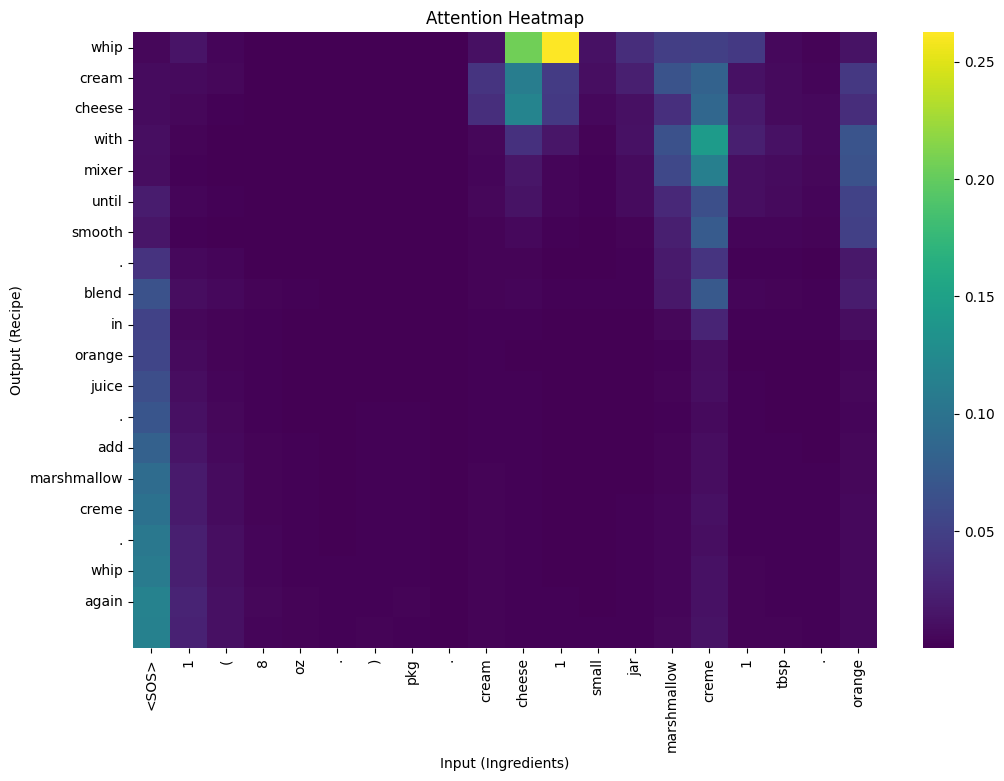

In [ ]:
model_attn.eval()

with torch.no_grad():

    src, trg = next(iter(test_loader))

    src = src.to(device)
    trg = trg.to(device)

    output, attentions = model_attn(
        src,
        trg,
        teacher_forcing_ratio=0
    )

# attentions:
# list of [batch,1,src_len]

# concat all decoding steps
attn_matrix = torch.cat(attentions, dim=1)

# first sample
sample_attn = attn_matrix[0]

# token decode
src_tokens = [
    idx2word[i.item()]
    for i in src[0]
]

trg_tokens = [
    idx2word[i.item()]
    for i in trg[0]
]

plot_attention(
    sample_attn,
    src_tokens,
    trg_tokens
)

**Discussion of the attention weights:**

The attention heatmap exhibits both meaningful alignments and several limitations in the learned attention behaviour. In the early decoding stages, the model demonstrates relatively clear phrase-level alignments, where output tokens such as “whip” and “cream” attend strongly to semantically related input tokens including “cheese”. This suggests that the attention mechanism successfully captures local ingredient-to-instruction relationships during the initial generation process.

However, as decoding progresses beyond the first sentence, the attention distributions become increasingly diffuse and less semantically focused. Later output tokens show a tendency to place substantial attention on punctuation or frequently occurring tokens rather than maintaining precise alignments with relevant ingredients. This behaviour suggests that the decoder gradually relies more on its accumulated hidden-state context and previously generated sequence structure rather than dynamically attending to the ingredient list.

In addition, the model fails to establish a strong alignment between the generated phrase “orange juice” and the input token “orange”, indicating limitations in long-range semantic matching and fine-grained ingredient grounding. Overall, the heatmap suggests that while the Bahdanau attention mechanism improves local alignment and contextual retrieval, the model still struggles to maintain stable and semantically precise attention over longer decoding sequences.


**What the attention mechanism learns:**

The attention mechanism learns meaningful alignments between ingredient tokens and generated recipe instructions. Rather than relying solely on a single encoder hidden state, the decoder dynamically attends to different parts of the input sequence depending on the current generation step. This enables the model to retrieve context-specific ingredient information during decoding.

The heatmaps suggest that the model learns both focused and distributed attention patterns. For ingredient-specific actions such as “whip”, the attention weights tend to concentrate on semantically related ingredient tokens such as “cream”, indicating that the model captures local ingredient-to-action relationships.

The attention mechanism also appears to reduce the information bottleneck present in the baseline encoder-decoder architecture by allowing direct access to all encoder outputs throughout generation. However, the visualisations further show that attention becomes more diffuse during longer decoding sequences, indicating that the model still struggles with maintaining stable long-range semantic alignment. Overall, the attention mechanism improves context-aware recipe generation and ingredient-to-step correspondence.


# Task 2 — Pre-trained Model Fine-tuning with LoRA

## T2.1 T5 Fine-tuning with LoRA

In [ ]:
!pip install transformers peft accelerate datasets sentencepiece bert-score -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 6.7 MB/s eta 0:00:00


In [ ]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
import pandas as pd
import numpy as np
import json
import torch

from torch.utils.data import Dataset

from transformers import (
    T5Tokenizer,
    T5ForConditionalGeneration,
    TrainingArguments,
    Trainer,
    DataCollatorForSeq2Seq
)

from peft import (
    LoraConfig,
    get_peft_model,
    TaskType
)

import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [ ]:
# ------------ 1. Load data ------------
base_path = "/content/drive/MyDrive/FIT5217/data/"

train_df = pd.read_csv(base_path + "train.csv")
dev_df = pd.read_csv(base_path + "dev.csv")
test_df = pd.read_csv(base_path + "test.csv")

In [ ]:
# ---------- 2. Parse JSON ----------
train_df['Ingredients'] = train_df['Ingredients'].apply(json.loads)
train_df['Recipe'] = train_df['Recipe'].apply(json.loads)

dev_df['Ingredients'] = dev_df['Ingredients'].apply(json.loads)
dev_df['Recipe'] = dev_df['Recipe'].apply(json.loads)

test_df['Ingredients'] = test_df['Ingredients'].apply(json.loads)
test_df['Recipe'] = test_df['Recipe'].apply(json.loads)

In [ ]:
def convert_ingredients(x):
    return " ; ".join(x)

def convert_recipe(x):
    return " ".join(x)

In [ ]:
train_df['input_text'] = train_df['Ingredients'].apply(convert_ingredients)
train_df['target_text'] = train_df['Recipe'].apply(convert_recipe)

dev_df['input_text'] = dev_df['Ingredients'].apply(convert_ingredients)
dev_df['target_text'] = dev_df['Recipe'].apply(convert_recipe)

test_df['input_text'] = test_df['Ingredients'].apply(convert_ingredients)
test_df['target_text'] = test_df['Recipe'].apply(convert_recipe)

In [ ]:
tokenizer = T5Tokenizer.from_pretrained('google-t5/t5-small')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
MAX_INPUT_LEN = 128
MAX_TARGET_LEN = 128

class RecipeDataset(Dataset):

    def __init__(self, dataframe, tokenizer):

        self.df = dataframe
        self.tokenizer = tokenizer

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        input_text = self.df.iloc[idx]['input_text']
        target_text = self.df.iloc[idx]['target_text']

        input_encoding = self.tokenizer(
            input_text,
            max_length=MAX_INPUT_LEN,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        target_encoding = self.tokenizer(
            target_text,
            max_length=MAX_TARGET_LEN,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        labels = target_encoding['input_ids'].squeeze()

        labels[labels == tokenizer.pad_token_id] = -100

        return {
            'input_ids': input_encoding['input_ids'].squeeze(),
            'attention_mask': input_encoding['attention_mask'].squeeze(),
            'labels': labels
        }

In [ ]:
train_dataset = RecipeDataset(train_df, tokenizer)
dev_dataset = RecipeDataset(dev_df, tokenizer)
test_dataset = RecipeDataset(test_df, tokenizer)

In [ ]:
from eval_metrics import evaluate2

[nltk_data] Downloading package punkt to /content/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /content/nltk_data...
[nltk_data] Downloading package omw-1.4 to /content/nltk_data...
[nltk_data] Downloading package punkt_tab to /content/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
def evaluate_model(model, tokenizer, dataframe, max_samples=300):

    predictions = []
    references = []

    model.eval()

    subset_df = dataframe.iloc[:max_samples]

    for _, row in subset_df.iterrows():

        input_text = row['input_text']
        gold_recipe = row['target_text']

        inputs = tokenizer(
            input_text,
            return_tensors='pt',
            truncation=True,
            max_length=MAX_INPUT_LEN
        ).to(DEVICE)

        with torch.no_grad():

            generated_ids = model.generate(
                input_ids=inputs['input_ids'],
                attention_mask=inputs['attention_mask'],
                max_new_tokens=64,
                num_beams=3,
                early_stopping=True
            )

        pred_text = tokenizer.decode(
            generated_ids[0],
            skip_special_tokens=True
        )

        predictions.append(pred_text)
        references.append(gold_recipe)

    metrics = evaluate2(references, predictions)
    return metrics

In [ ]:
def run_lora_experiment(
    experiment_name,
    lora_r,
    lora_alpha,
    lora_dropout,
    target_modules
):

    print(f"\n========== {experiment_name} ==========")

    # Load base T5
    model = T5ForConditionalGeneration.from_pretrained(
        'google-t5/t5-small'
    )

    # LoRA configuration
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_2_SEQ_LM,
        r=lora_r,
        lora_alpha=lora_alpha,
        lora_dropout=lora_dropout,
        target_modules=target_modules,
        bias='none'
    )

    # Add LoRA
    model = get_peft_model(model, lora_config)

    model.print_trainable_parameters()

    model.to(DEVICE)

    # Training arguments
    training_args = TrainingArguments(
        output_dir=f'./{experiment_name}',

        eval_strategy='epoch',
        save_strategy='epoch',

        learning_rate=5e-4,

        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,

        # gradient_accumulation_steps=4,  # updatte parameters every 4 batches

        num_train_epochs=5,

        weight_decay=0.01,

        logging_steps=100,

        load_best_model_at_end=True,

        save_total_limit=1,

        fp16=torch.cuda.is_available(),

        report_to='none'
    )

    # Data collator
    data_collator = DataCollatorForSeq2Seq(
        tokenizer=tokenizer,
        model=model
    )

    # Trainer
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=dev_dataset,
        data_collator=data_collator
    )

    # Train
    trainer.train()

    # -------- loss curve --------

    log_history = trainer.state.log_history

    train_losses = []
    eval_losses = []
    epochs = []

    for log in log_history:

        if 'loss' in log and 'epoch' in log:
            train_losses.append(log['loss'])

        if 'eval_loss' in log and 'epoch' in log:
            eval_losses.append(log['eval_loss'])
            epochs.append(log['epoch'])

    import matplotlib.pyplot as plt

    plt.figure(figsize=(8,5))

    plt.plot(
        epochs,
        train_losses[:len(epochs)],
        label='Training Loss'
    )

    plt.plot(
        epochs,
        eval_losses,
        label='Validation Loss'
    )

    plt.xlabel('Epoch')
    plt.ylabel('Loss')

    plt.title(f'Loss Curve - {experiment_name}')

    plt.legend()

    plt.show()

    # Evaluate on dev split
    metrics = evaluate_model(
        model,
        tokenizer,
        dev_df,
        max_samples=len(dev_df)
    )

    return model, metrics


========== lora_r8, alpha_16 ==========


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

trainable params: 294,912 || all params: 60,801,536 || trainable%: 0.4850


Epoch,Training Loss,Validation Loss
1,2.676439,2.482800
2,2.637855,2.404906
3,2.616872,2.373615
4,2.612207,2.354504
5,2.573387,2.347975


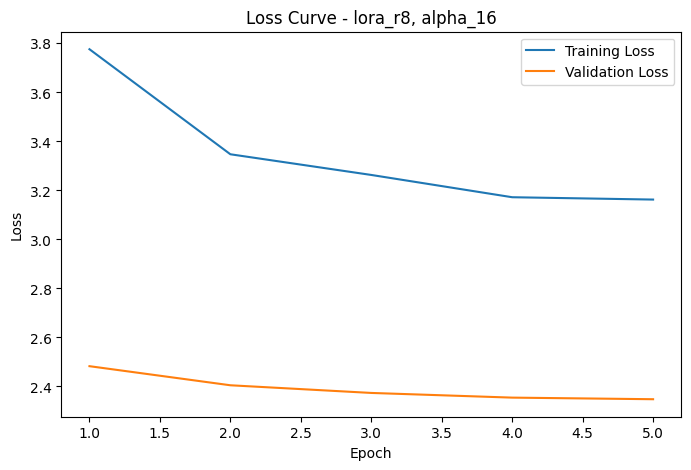

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BLEU-4:    0.0776
METEOR:    0.2350
BERTScore: 0.8791


In [ ]:
model_1, metrics_1 = run_lora_experiment(
    experiment_name='lora_r8, alpha_16',
    lora_r=8,
    lora_alpha=16,
    lora_dropout=0.1,
    target_modules=['q', 'v']
)


========== lora_r8, alpha_32 ==========


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

trainable params: 294,912 || all params: 60,801,536 || trainable%: 0.4850


Epoch,Training Loss,Validation Loss
1,2.629816,2.441415
2,2.605233,2.367468
3,2.585280,2.335853


Epoch,Training Loss,Validation Loss
1,2.629816,2.441415
2,2.605233,2.367468
3,2.585280,2.335853
4,2.578596,2.318159
5,2.537895,2.312210


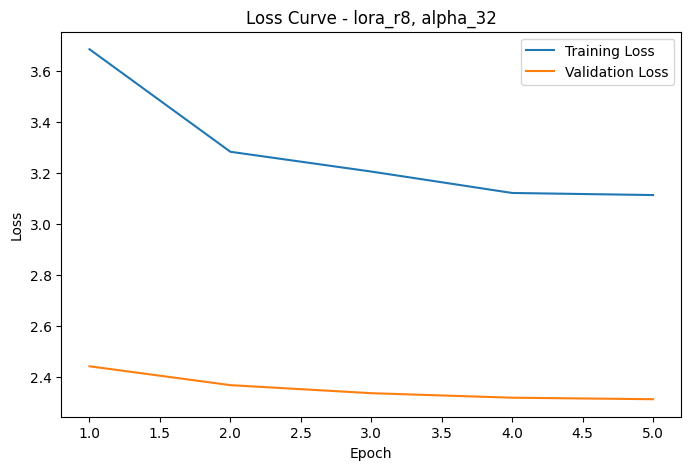

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BLEU-4:    0.0813
METEOR:    0.2407
BERTScore: 0.8797


In [ ]:
model_2, metrics_2 = run_lora_experiment(
    experiment_name='lora_r8, alpha_32',
    lora_r=8,
    lora_alpha=32,
    lora_dropout=0.1,
    target_modules=['q', 'v']
)


========== lora_r16, alpha_32 ==========


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

trainable params: 589,824 || all params: 61,096,448 || trainable%: 0.9654


Epoch,Training Loss,Validation Loss
1,2.584849,2.405491
2,2.540403,2.313381
3,2.511158,2.275126
4,2.499185,2.253836
5,2.457740,2.245421


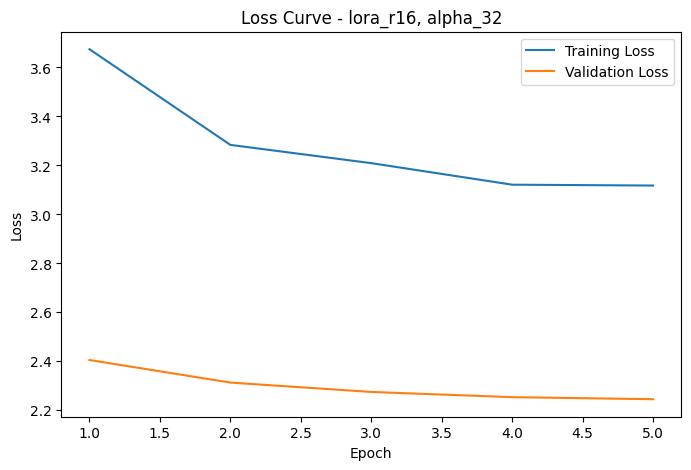

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BLEU-4:    0.0816
METEOR:    0.2436
BERTScore: 0.8806


In [ ]:
model_3, metrics_3 = run_lora_experiment(
    experiment_name='lora_r16, alpha_32',
    lora_r=16,
    lora_alpha=32,
    lora_dropout=0.1,
    target_modules=['q', 'v']
)

In [ ]:
# compare results
results_df = pd.DataFrame([
    {
        'Config': 'r=8，alpha=16',
        **metrics_1
    },
    {
        'Config': 'r=8，alpha=32',
        **metrics_2
    },
    {
        'Config': 'r=16，alpha=32',
        **metrics_3
    }
])

results_df

,Config,BLEU-4,METEOR,BERTScore
0,r=8，alpha=16,0.077635,0.234986,0.879098
1,r=8，alpha=32,0.081314,0.240667,0.879717
2,r=16，alpha=32,0.081602,0.243635,0.880565


In [ ]:
# select best nidel
results_df.sort_values(
    by='BERTScore',
    ascending=False
)

,Config,BLEU-4,METEOR,BERTScore
2,r=16，alpha=32,0.081602,0.243635,0.880565
1,r=8，alpha=32,0.081314,0.240667,0.879717
0,r=8，alpha=16,0.077635,0.234986,0.879098


**Comparison of different configurations:**

Three different LoRA configurations were evaluated by varying the rank parameter (`lora_r`) and scaling factor (`lora_alpha`). Overall, increasing both the rank and scaling factor led to gradual improvements across BLEU-4, METEOR, and BERTScore. Increasing `lora_alpha` from 16 to 32 while keeping `r=8` improved all evaluation metrics, suggesting that a larger scaling factor allowed stronger adaptation updates during fine-tuning.

Further increasing the rank from `r=8` to `r=16` produced additional but relatively modest gains. This indicates that higher-rank low-dimensional updates improved the model’s capacity to capture task-specific patterns in recipe generation. However, the performance improvements were incremental rather than dramatic, suggesting diminishing returns from increasing LoRA complexity.

The BERTScore values remained consistently high across all configurations, indicating that all models achieved strong semantic similarity to the reference recipes. In contrast, BLEU-4 and METEOR showed more noticeable improvements, suggesting that larger LoRA configurations mainly improved token-level alignment and lexical coherence. Overall, the experiments demonstrate that LoRA can achieve effective adaptation with only a small number of trainable parameters.


In [ ]:
def evaluate_prediction_model(model, tokenizer, dataframe, max_samples=300):

    predictions = []
    references = []

    model.eval()

    subset_df = dataframe.iloc[:max_samples]

    for _, row in subset_df.iterrows():

        input_text = row['input_text']
        gold_recipe = row['target_text']

        inputs = tokenizer(
            input_text,
            return_tensors='pt',
            truncation=True,
            max_length=MAX_INPUT_LEN
        ).to(DEVICE)

        with torch.no_grad():

            generated_ids = model.generate(
                input_ids=inputs['input_ids'],
                attention_mask=inputs['attention_mask'],
                max_new_tokens=64,
                num_beams=3,
                early_stopping=True
            )

        pred_text = tokenizer.decode(
            generated_ids[0],
            skip_special_tokens=True
        )

        predictions.append(pred_text)
        references.append(gold_recipe)

    metrics = evaluate2(references, predictions)
    return metrics, predictions

In [ ]:
# final test evaluation
final_test_metrics, test_predictions = evaluate_prediction_model(
    model_3,
    tokenizer,
    test_df,
    max_samples=len(test_df)
)

print(final_test_metrics)

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BLEU-4:    0.0809
METEOR:    0.2408
BERTScore: 0.8811
{'BLEU-4': 0.08089657177761672, 'METEOR': np.float64(0.24081974800679498), 'BERTScore': np.float32(0.8810789)}


**Interpretation of Scores:**

The T5 model fine-tuned with LoRA substantially outperformed both the baseline and attention-based RNN models. The higher BLEU-4 and METEOR scores indicate that the generated recipes exhibited stronger token-level alignment, better lexical overlap, and more coherent recipe structures. In addition, the high BERTScore suggests that the generated recipes were semantically very similar to the reference recipes, even when exact wording differed. These improvements are likely due to T5’s pre-trained encoder-decoder architecture, which captures richer linguistic and contextual knowledge than models trained from scratch. Furthermore, LoRA enabled parameter-efficient fine-tuning while still allowing the model to adapt effectively to the recipe generation task.


In [ ]:
save_path = "/content/drive/MyDrive/FIT5217/generated_34683720.xlsx"

submission_df = pd.read_excel(save_path)

submission_df["Recipe_T2_T5"] = test_predictions

submission_df.to_excel(save_path, index=False)

print("T5 predictions appended successfully!")

T5 predictions appended successfully!


## T2.2 GPT-2 Fine-tuning with LoRA

In [ ]:
!pip install -q transformers datasets peft accelerate evaluate bert-score nltk


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 7.0 MB/s eta 0:00:00


In [ ]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
!pip uninstall -y \
transformers \
tokenizers \
peft \
accelerate \
sentence-transformers

!pip install -q \
transformers==4.38.2 \
tokenizers==0.15.2 \
peft==0.10.0 \
accelerate==0.27.2 \
sentence-transformers==2.6.1 \
bert-score==0.3.13

Found existing installation: transformers 5.0.0
Uninstalling transformers-5.0.0:
  Successfully uninstalled transformers-5.0.0
Found existing installation: tokenizers 0.22.2
Uninstalling tokenizers-0.22.2:
  Successfully uninstalled tokenizers-0.22.2
Found existing installation: peft 0.19.1
Uninstalling peft-0.19.1:
  Successfully uninstalled peft-0.19.1
Found existing installation: accelerate 1.13.0
Uninstalling accelerate-1.13.0:
  Successfully uninstalled accelerate-1.13.0
Found existing installation: sentence-transformers 5.4.1
Uninstalling sentence-transformers-5.4.1:
  Successfully uninstalled sentence-transformers-5.4.1
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.7/130.7 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 87.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 99.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.1/199.1 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.0

In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling,
    EarlyStoppingCallback
)

from peft import (
    LoraConfig,
    get_peft_model,
    TaskType
)


import nltk
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
save_path = "/content/drive/MyDrive/FIT5217/processed/"

train_df = pd.read_pickle(save_path + "train.pkl")
dev_df   = pd.read_pickle(save_path + "dev.pkl")
test_df  = pd.read_pickle(save_path + "test.pkl")

print(len(train_df), len(dev_df), len(test_df))

162899 1065 1081


In [ ]:
# Build GPT-2 Training Text
"""
 GPT-2 is decoder-only
# We concatenate:
#
# Ingredients ---> Recipe
#
# Example:
#
# Ingredients:
# sugar milk butter
#
# Recipe:
# mix ingredients ...
"""

def build_prompt(ingredients, recipe=None):

    if isinstance(ingredients, list):
        ingredients = " ".join(ingredients)

    text = f"Ingredients:\n{ingredients}\n\nRecipe:\n"

    if recipe is not None:

        if isinstance(recipe, list):
            recipe = " ".join(recipe)

        text += recipe

    return text

In [ ]:
#  Convert DataFrames

train_texts = [
    build_prompt(row["Ingredients"], row["Recipe"])
    for _, row in train_df.iterrows()
]

dev_texts = [
    build_prompt(row["Ingredients"], row["Recipe"])
    for _, row in dev_df.iterrows()
]

test_prompts = [
    build_prompt(row["Ingredients"])
    for _, row in test_df.iterrows()
]

test_references = [
    " ".join(r) if isinstance(r, list) else str(r)
    for r in test_df["Recipe"]
]

In [ ]:
# Load GPT-2 Tokenizer


model_name = "openai-community/gpt2"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# GPT-2 has no PAD token
tokenizer.pad_token = tokenizer.eos_token

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
# Tokenization

MAX_LEN = 256

def tokenize_function(examples):

    outputs = tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LEN
    )

    outputs["labels"] = outputs["input_ids"].copy()

    return outputs

train_dataset = Dataset.from_dict({
    "text": train_texts
})

dev_dataset = Dataset.from_dict({
    "text": dev_texts
})

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

dev_dataset = dev_dataset.map(
    tokenize_function,
    batched=True
)

train_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

dev_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

Map:   0%|          | 0/162899 [00:00<?, ? examples/s]

Map:   0%|          | 0/1065 [00:00<?, ? examples/s]

In [ ]:
# Load GPT-2 Model


model = AutoModelForCausalLM.from_pretrained(model_name)

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [ ]:
# LoRA Configuration

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    inference_mode=False,

    r=8,
    lora_alpha=16,
    lora_dropout=0.1,

    target_modules=["c_attn"]
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.23643136409814364


/usr/local/lib/python3.12/dist-packages/peft/tuners/lora/layer.py:1059: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


In [ ]:
#  Data Collator

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

In [ ]:
#  Training Arguments

training_args = TrainingArguments(

    output_dir="./gpt2_lora",

    evaluation_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-4,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    num_train_epochs=5,

    weight_decay=0.01,

    logging_steps=100,

    load_best_model_at_end=True,

    metric_for_best_model="eval_loss",

    greater_is_better=False,

    save_total_limit=2,

    fp16=torch.cuda.is_available(),

    report_to="none"
)

In [ ]:
# Trainer

trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=train_dataset,

    tokenizer=tokenizer,

    eval_dataset=dev_dataset,

    data_collator=data_collator,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)


/usr/local/lib/python3.12/dist-packages/accelerate/accelerator.py:450: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)


In [ ]:
# Train

train_result = trainer.train()

Epoch,Training Loss,Validation Loss
1,2.191300,2.034133
2,2.127300,1.996762


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Epoch,Training Loss,Validation Loss
1,2.191300,2.034133
2,2.127300,1.996762
3,2.105800,1.975801
4,2.090300,1.964546
5,2.103500,1.960910


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [ ]:
# Save Model

trainer.save_model("/content/drive/MyDrive/FIT5217/processed/gpt2_lora")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


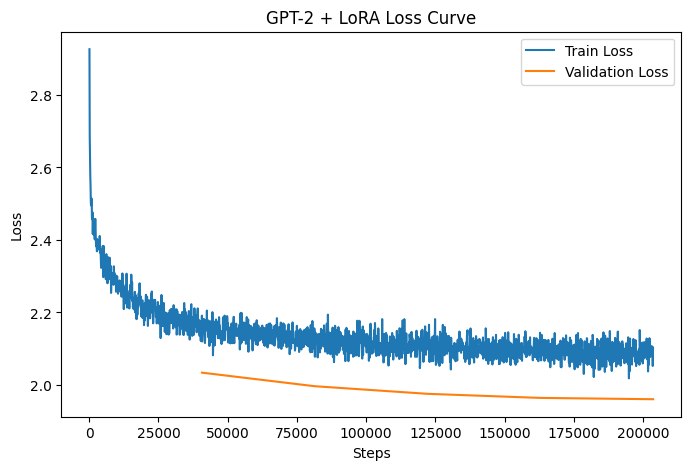

In [ ]:
# Plot Loss Curve

logs = trainer.state.log_history

train_loss = []
eval_loss = []

train_steps = []
eval_steps = []

for log in logs:

    if "loss" in log and "eval_loss" not in log:
        train_loss.append(log["loss"])
        train_steps.append(log["step"])

    if "eval_loss" in log:
        eval_loss.append(log["eval_loss"])
        eval_steps.append(log["step"])

plt.figure(figsize=(8,5))

plt.plot(train_steps, train_loss, label="Train Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")

plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("GPT-2 + LoRA Loss Curve")

plt.legend()
plt.show()

In [ ]:
# Generation Function

def generate_recipe(
    prompt,
    strategy="greedy"
):

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LEN
    ).to(device)

    model.to(device)
    model.eval()

    with torch.no_grad():

        if strategy == "greedy":

            outputs = model.generate(

                **inputs,

                max_new_tokens=80,

                do_sample=False,

                num_beams=1,

                pad_token_id=tokenizer.eos_token_id
            )

        elif strategy == "beam":

            outputs = model.generate(

                **inputs,

                max_new_tokens=80,

                num_beams=3,

                early_stopping=True,

                do_sample=False,

                pad_token_id=tokenizer.eos_token_id
            )

    decoded = tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    # keep only generated recipe
    recipe = decoded.split("Recipe:\n")[-1]

    return recipe.strip()

In [ ]:
# Generate Predictions

greedy_predictions = []
beam_predictions = []

for prompt in test_prompts:

    greedy_text = generate_recipe(
        prompt,
        strategy="greedy"
    )

    beam_text = generate_recipe(
        prompt,
        strategy="beam"
    )

    greedy_predictions.append(greedy_text)
    beam_predictions.append(beam_text)

In [ ]:
save_path = "/content/drive/MyDrive/FIT5217/generated_34683720.xlsx"

submission_df = pd.read_excel(save_path)

submission_df["Recipe_T2_GPT2"] = beam_predictions

submission_df.to_excel(save_path, index=False)

print("GPT2 predictions appended successfully!")

GPT2 predictions appended successfully!


In [ ]:
# Evaluation Metrics
from eval_metrics import evaluate2

greedy_metrics = evaluate2(test_references,greedy_predictions)
beam_metrics = evaluate2(test_references,beam_predictions)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BLEU-4:    0.0446
METEOR:    0.2074
BERTScore: 0.8342


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BLEU-4:    0.0567
METEOR:    0.2461
BERTScore: 0.8506


**Interpretation of Scores:**

The GPT-2 model fine-tuned with LoRA achieved moderate generation performance, with BLEU-4 scores around 0.04–0.06, METEOR scores around 0.21–0.25, and BERTScore values above 0.83. The relatively low BLEU-4 scores indicate that the generated recipes often differed from the reference recipes at the exact n-gram level, which is common in open-ended text generation tasks. However, the higher METEOR and BERTScore values suggest that the model still captured meaningful recipe semantics and cooking-related language patterns. Overall, GPT-2 generated fluent recipe instructions but still struggled with precise ingredient grounding and long-range recipe planning compared to encoder-decoder architectures such as T5.

**Decoding Strategy Comparison:**

Beam search consistently outperformed greedy decoding across all evaluation metrics. BLEU-4 improved from 0.0446 to 0.0567, METEOR improved from 0.2074 to 0.2461, and BERTScore increased from 0.8342 to 0.8506. These improvements suggest that beam search generates more coherent and semantically aligned recipes by exploring multiple candidate sequences during decoding rather than selecting only the most probable token at each step. The improvement in METEOR particularly indicates better lexical diversity and recipe structure. However, the performance gains were relatively moderate, suggesting that GPT-2’s decoder-only architecture still has limitations in conditioning generation strongly on the ingredient inputs.



# Task 3 — Menu Designer: RAG and LLM-as-Judge

## T3.1 Knowledge Base Construction

#### Implement Retrieval Logic

To support the RAG pipeline, a BM25-based retrieval system was implemented to search for relevant recipes from the full Cooking Dataset.

First, all recipes from the train, dev, and test splits were converted into retrieval documents containing the recipe title and ingredients. These documents were tokenized and indexed using the BM25 algorithm.

Given a user query (e.g., "Give me some chicken recipes"), the query is preprocessed and tokenized, then compared against all indexed documents using BM25 scoring. The retrieval system ranks all recipes according to their relevance scores and returns the top-5 most relevant recipes.

This retrieval step provides contextual recipe information for the downstream menu generation stage in the RAG pipeline.

###### Reason for choosing BM25

I selected BM25 because the recipe dataset is highly structured and keyword-rich.
Queries such as “chicken recipes” or “Italian recipes” depend heavily on ingredient and cuisine keyword overlap, making sparse lexical retrieval highly effective.
BM25 is computationally efficient, interpretable, and stable without requiring GPU resources or additional embedding model training.

In [ ]:
!pip install rank_bm25

In [ ]:
import pandas as pd
import numpy as np
import time
from rank_bm25 import BM25Okapi

#### Load dataset

In [ ]:
save_path = "/content/drive/MyDrive/FIT5217/processed/"

train_df = pd.read_pickle(save_path + "train.pkl")
dev_df   = pd.read_pickle(save_path + "dev.pkl")
test_df  = pd.read_pickle(save_path + "test.pkl")

In [ ]:
# Merge full dataset
# (train + dev + test)

full_df = pd.concat(
    [train_df, dev_df, test_df],
    ignore_index=True
)

print("Total recipes:", len(full_df))

Total recipes: 165045


In [ ]:
print(full_df.columns)

Index(['Title', 'Ingredients', 'Recipe', 'ing_tokens', 'rec_tokens', 'ing_ids',
       'rec_ids'],
      dtype='object')


#### Build retrieval documents

In [ ]:
documents = []

for _, row in full_df.iterrows():

    # --------------------------------------------------------
    # Convert ingredients into text
    # --------------------------------------------------------

    if isinstance(row["Ingredients"], list):
        ingredients_text = " ".join(row["Ingredients"])
    else:
        ingredients_text = str(row["Ingredients"])

    # --------------------------------------------------------
    # Get title if exists
    # --------------------------------------------------------

    if "Title" in full_df.columns:
        title_text = str(row["Title"])
    else:
        title_text = "Unknown Recipe"

    # --------------------------------------------------------
    # Final retrieval document （title + ingredients)
    # --------------------------------------------------------

    doc = f"""
    Title: {title_text}

    Ingredients:
    {ingredients_text}
    """

    documents.append(doc)


print("Number of retrieval documents:", len(documents))

Number of retrieval documents: 165045


#### Tokenize documents

In [ ]:
tokenized_docs = []

for doc in documents:

    tokens = doc.lower().split()

    tokenized_docs.append(tokens)


print("Tokenization complete.")

Tokenization complete.


#### Build BM25 index


In [ ]:
start_time = time.time()

bm25 = BM25Okapi(tokenized_docs)

end_time = time.time()

indexing_time = end_time - start_time

print(f"BM25 indexing completed in {indexing_time:.4f} seconds")

BM25 indexing completed in 2.3059 seconds


In [ ]:
# save index
import os
SAVE_DIR = '/content/drive/MyDrive/FIT5217/T3/'
os.makedirs(SAVE_DIR, exist_ok=True)

import pickle
with open(os.path.join(SAVE_DIR, 'bm25_index.pkl'), 'wb') as f:
    pickle.dump(bm25, f)
print("BM25 index saved.")

BM25 index saved.


In [ ]:
# save retrieval documents

with open(SAVE_DIR + "retrieval_docs.pkl", "wb") as f:

    pickle.dump(documents, f)

print("Retrieval documents saved.")

Retrieval documents saved.


In [ ]:
# save tokenized docs

with open(SAVE_DIR + "tokenized_docs.pkl", "wb") as f:

    pickle.dump(tokenized_docs, f)

print("Tokenized documents saved.")

Tokenized documents saved.


In [ ]:
# save full recipe dataframe

full_df.to_pickle(
    SAVE_DIR + "full_recipe_data.pkl"
)

print("Full recipe dataframe saved.")

Full recipe dataframe saved.


#### Retrieval function

In [ ]:
# Query processing
STOPWORDS = {
    "give", "me", "some",
    "a", "an", "the",
    "recipe", "recipes"
}

def preprocess_query(query):

    tokens = query.lower().split()

    tokens = [
        token for token in tokens
        if token not in STOPWORDS
    ]

    return tokens

In [ ]:
def retrieve_recipes(query, top_k=5, verbose=True):
    start_time = time.time()

    # --------------------------------------------------------
    # Tokenize query
    # --------------------------------------------------------

    query_tokens = preprocess_query(query)

    # --------------------------------------------------------
    # Compute BM25 scores
    # --------------------------------------------------------

    scores = bm25.get_scores(query_tokens)

    # --------------------------------------------------------
    # Get top-k indices
    # --------------------------------------------------------

    top_indices = np.argsort(scores)[::-1][:top_k]
    latency = time.time() - start_time

    # ---------------------------
    # display results
    # ---------------------------

    print("=" * 70)
    print(f"QUERY: {query}")
    print("=" * 70)

    print(f"\nRetrieval latency: {latency:.4f} seconds")

    results = []

    for rank, idx in enumerate(top_indices):

        row = full_df.iloc[idx]

        title = row["Title"]

        ingredients = row["Ingredients"]

        recipe = row["Recipe"]

        score = scores[idx]

        if verbose:

            print("\n" + "-" * 50)

            print(f"Top {rank+1}")
            print(f"BM25 Score: {score:.4f}")

            print(f"\nTitle: {title}")

            print(f"\nIngredients:")
            print(ingredients)

            print(f"\nRecipe:")
            print(recipe)

            results.append({
                "title": title,
                "ingredients": ingredients,
                "recipe": recipe,
                "score": score
            })

    return results

#### KB Statistics

In [ ]:
# Number of indexed documents
num_docs = len(documents)

# Average document length
avg_doc_length = np.mean(
    [len(doc.split()) for doc in documents]
)

print("\n========== KB Statistics ==========")

print("Indexed documents:", num_docs)

print(f"Average document length: {avg_doc_length:.2f} tokens")

print(f"Indexing time: {indexing_time:.4f} seconds")


========== KB Statistics ==========
Indexed documents: 165045
Average document length: 36.08 tokens
Indexing time: 2.3059 seconds


In [ ]:
# Measure retrieval latency
sample_query = "chicken recipes"

start_time = time.time()

_ = retrieve_recipes(sample_query,1, False)

end_time = time.time()

retrieval_latency = end_time - start_time

print(f"\nRetrieval latency: {retrieval_latency:.4f} seconds")

QUERY: chicken recipes

Retrieval latency: 0.0999 seconds

Retrieval latency: 0.1007 seconds


#### Demonstration Queries

In [ ]:
retrieve_recipes("Give me some chicken recipes")

QUERY: Give me some chicken recipes

Retrieval latency: 0.0869 seconds

--------------------------------------------------
Top 1
BM25 Score: 4.5950

Title: Chicken Pie

Ingredients:
['1 chicken', '1 1/2 c. chicken broth', '1 can cream of chicken soup, undiluted']

Recipe:
['Boil chicken until tender, then debone.', 'Cut up chicken and put in casserole.', 'Combine soup and broth and pour over chicken.']

--------------------------------------------------
Top 2
BM25 Score: 4.5377

Title: Chicken And Dumplings

Ingredients:
['4 chicken breasts', 'about 3 qt. water', '2 chicken bouillon cubes', '1 can chicken soup']

Recipe:
['Cook the chicken breasts (with skin left on) in the water until tender. Remove chicken. Add the bouillon cubes and chicken soup to broth. Heat until it comes to a rolling boil. Debone chicken and add back to broth.']

--------------------------------------------------
Top 3
BM25 Score: 4.5096

Title: Chicken Dumplings

Ingredients:
['1 lb. chicken', '2 cans cream of 

[{'title': 'Chicken Pie',
  'ingredients': ['1 chicken',
   '1 1/2 c. chicken broth',
   '1 can cream of chicken soup, undiluted'],
  'recipe': ['Boil chicken until tender, then debone.',
   'Cut up chicken and put in casserole.',
   'Combine soup and broth and pour over chicken.'],
  'score': np.float64(4.59501482029904)},
 {'title': 'Chicken And Dumplings',
  'ingredients': ['4 chicken breasts',
   'about 3 qt. water',
   '2 chicken bouillon cubes',
   '1 can chicken soup'],
  'recipe': ['Cook the chicken breasts (with skin left on) in the water until tender. Remove chicken. Add the bouillon cubes and chicken soup to broth. Heat until it comes to a rolling boil. Debone chicken and add back to broth.'],
  'score': np.float64(4.53768683658173)},
 {'title': 'Chicken Dumplings',
  'ingredients': ['1 lb. chicken',
   '2 cans cream of chicken soup',
   '2 cans canned biscuits',
   '2 chicken bouillon cubes'],
  'recipe': ['Boil chicken in water until done.',
   'Remove chicken from bones, 

In [ ]:
retrieve_recipes("Give me some dessert recipes")

QUERY: Give me some dessert recipes

Retrieval latency: 0.0947 seconds

--------------------------------------------------
Top 1
BM25 Score: 7.0328

Title: Brazilian Bananas

Ingredients:
['6 bananas', '2 Tbsp. rum', '2 dessert spoons instant coffee', '2 dessert spoons fine sugar', '8 fl. oz. heavy cream', 'toasted slivered almonds']

Recipe:
['Slice bananas thickly into individual dishes and sprinkle with rum.', 'Dissolve coffee in 3 to 4 tablespoons hot water.', 'Add sugar; stir well and leave until cold.', 'Whip cream and gradually stir into coffee mixture.', 'Spoon over bananas.', 'Sprinkle with slivered almonds and serve chilled.']

--------------------------------------------------
Top 2
BM25 Score: 6.9635

Title: Quick Dessert

Ingredients:
['bananas', 'shredded coconut', 'honey']

Recipe:
['Cut bananas in circles.', 'Layer on plate.', 'Put shredded coconut on top, then put honey on top.', 'Eat with fork or fingers.', 'Great for us kids.']

--------------------------------------

[{'title': 'Brazilian Bananas',
  'ingredients': ['6 bananas',
   '2 Tbsp. rum',
   '2 dessert spoons instant coffee',
   '2 dessert spoons fine sugar',
   '8 fl. oz. heavy cream',
   'toasted slivered almonds'],
  'recipe': ['Slice bananas thickly into individual dishes and sprinkle with rum.',
   'Dissolve coffee in 3 to 4 tablespoons hot water.',
   'Add sugar; stir well and leave until cold.',
   'Whip cream and gradually stir into coffee mixture.',
   'Spoon over bananas.',
   'Sprinkle with slivered almonds and serve chilled.'],
  'score': np.float64(7.032757773905013)},
 {'title': 'Quick Dessert',
  'ingredients': ['bananas', 'shredded coconut', 'honey'],
  'recipe': ['Cut bananas in circles.',
   'Layer on plate.',
   'Put shredded coconut on top, then put honey on top.',
   'Eat with fork or fingers.',
   'Great for us kids.'],
  'score': np.float64(6.963488639743433)},
 {'title': 'Foil Dessert',
  'ingredients': ['glazed donuts', 'sliced pineapple', 'large marshmallows'],
  '

In [ ]:
retrieve_recipes("Give me some Italian recipes")

QUERY: Give me some Italian recipes

Retrieval latency: 0.0924 seconds

--------------------------------------------------
Top 1
BM25 Score: 6.8385

Title: Open-Faced Italian Pork Sandwich

Ingredients:
['8 thin boneless pork loin chops', 'Italian dressing', 'oil', 'sliced Italian bread']

Recipe:
['Marinate pork chops in Italian dressing for 10 minutes. Remove pork from marinade and brown quickly in hot skillet with 1 tablespoon oil.', 'Season with salt and pepper; serve on Italian bread.', 'Serve with sliced cucumbers and cherry tomatoes to garnish.', 'Add lettuce and purple onions to sandwich.', 'Serves 4.']

--------------------------------------------------
Top 2
BM25 Score: 6.8385

Title: Italian Potatoes

Ingredients:
['4 raw potatoes', '1/2 to 1 c. Italian salad dressing', 'Italian seasoning', 'onion (optional)']

Recipe:
['Cut potatoes into squares.', 'Add onion, Italian dressing and Italian seasoning to taste.', 'Microwave for 15 minutes or oven cook until done.']

----------

[{'title': 'Open-Faced Italian Pork Sandwich',
  'ingredients': ['8 thin boneless pork loin chops',
   'Italian dressing',
   'oil',
   'sliced Italian bread'],
  'recipe': ['Marinate pork chops in Italian dressing for 10 minutes. Remove pork from marinade and brown quickly in hot skillet with 1 tablespoon oil.',
   'Season with salt and pepper; serve on Italian bread.',
   'Serve with sliced cucumbers and cherry tomatoes to garnish.',
   'Add lettuce and purple onions to sandwich.',
   'Serves 4.'],
  'score': np.float64(6.838532172088838)},
 {'title': 'Italian Potatoes',
  'ingredients': ['4 raw potatoes',
   '1/2 to 1 c. Italian salad dressing',
   'Italian seasoning',
   'onion (optional)'],
  'recipe': ['Cut potatoes into squares.',
   'Add onion, Italian dressing and Italian seasoning to taste.',
   'Microwave for 15 minutes or oven cook until done.'],
  'score': np.float64(6.838532172088838)},
 {'title': 'Italian Shrimp',
  'ingredients': ['shrimp', '1 bottle Italian dressing'],

#### Commentary on Retrieval Quality

The BM25 retrieval system successfully returned recipes relevant to the user queries through keyword-based matching.

For the chicken-related query, the top retrieved recipes consistently contained chicken-related ingredients and cooking instructions, such as “Chicken Pie”, “Chicken and Dumplings”, and “Chicken Casserole”. This indicates that the retrieval system effectively captured ingredient-level relevance using lexical matching.

For the dessert query, the retrieval system returned multiple dessert-style dishes including banana desserts, sweet snacks, and dessert beverages. The retrieved recipes showed strong alignment with dessert-related keywords and ingredients.

For the Italian query, the retrieval system successfully retrieved recipes containing explicit Italian-related terms such as “Italian dressing”, “Italian bread”, and “Italian seasoning”. This demonstrates that BM25 performed well when cuisine-specific keywords were present in recipe titles or ingredients.

Overall, BM25 provided stable and computationally efficient retrieval performance for the recipe dataset. The retrieval quality improved significantly after query preprocessing and stopword removal, which reduced noise from non-informative query terms. However, because BM25 relies primarily on lexical overlap, retrieval performance may still be limited for queries requiring deeper semantic understanding or implicit cuisine relationships.

## T3.2 RAG Pipeline for Menu Generation

In [ ]:
!pip install groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.3/142.3 kB 5.4 MB/s eta 0:00:00


In [ ]:
from groq import Groq
import os

from getpass import getpass

# ----------------------------------------
# securely input API key
# ----------------------------------------

if not os.getenv("GROQ_API_KEY"):

    os.environ["GROQ_API_KEY"] = getpass(
        "Enter your Groq API key: "
    )

# ----------------------------------------
# create Groq client
# ----------------------------------------

client = Groq(
    api_key=os.environ["GROQ_API_KEY"]
)

print("Groq client initialized successfully.")

Enter your Groq API key: ··········
Groq client initialized successfully.


In [ ]:
client = Groq(
    api_key=os.environ["GROQ_API_KEY"]
)

#### Advanced Extension: Few-shot Prompting

To improve menu structure consistency and constraint-following behavior, a few-shot prompting strategy was added to the RAG pipeline.

A demonstration menu example was included in the prompt before the user query and retrieved recipes. This guided the LLM toward generating menus with clearer course structures, explicit recipe references, and more reliable constraint explanations.

Few-shot prompting improved the overall formatting consistency and reduced incomplete menu outputs.

In [ ]:
few_shot_example = """

Example Menu:

Starter:

- Dish Name & Description:
Italian Herb Bread served warm with olive oil and oregano seasoning. The bread is lightly toasted to create a crisp outer texture while maintaining a soft interior. The preparation is simple and realistic for a light Italian-style starter.

- Inspired by:
Italian Bread

- Why it satisfies the request:
This starter reflects Italian cuisine through the use of Italian bread, olive oil, and oregano-based seasoning directly inspired by the retrieved recipe. Its light portion size and simple preparation make it suitable as a starter course.

--------------------------------------------------

Main Course:

- Dish Name & Description:
Chicken And Dumplings prepared by simmering tender chicken with vegetables in a savory broth before adding soft dumplings to finish the dish. The cooking sequence follows realistic preparation steps and creates a hearty main course with balanced flavor and texture.

- Inspired by:
Chicken And Dumplings

- Why it satisfies the request:
This dish provides a filling chicken-based main course using ingredients and cooking techniques directly inspired by the retrieved recipe. The rich broth and dumplings make it appropriate as the central dish of the menu.

--------------------------------------------------

Dessert:

- Dish Name & Description:
Quick Dessert featuring a light sweet pastry with vanilla flavor and a simple baked preparation process. The dessert is intentionally uncomplicated to complement the heavier main course without overwhelming the overall menu balance.

- Inspired by:
Quick Dessert

- Why it satisfies the request:
This dessert offers a simple sweet ending inspired by the retrieved recipe while maintaining a balanced progression across the full 3-course menu. Its light sweetness makes it suitable as a final dessert course.

"""

#### Prompt Construction

In [ ]:
def build_prompt(user_query, retrieved_results, few_shot_example=""):
    # --------------------------------------------------------
    # 1. System Instruction & Role
    # --------------------------------------------------------
    prompt = """
You are a world-class professional chef and menu designer.

Your task is to generate a realistic, coherent, and high-quality 3-course menu
(Starter, Main Course, Dessert) using the USER REQUEST and the RETRIEVED RECIPES.

CRITICAL DIRECTIONS:

1. Dietary and cultural constraints from the USER REQUEST are the HIGHEST PRIORITY and must NEVER be violated.

2. Every course MUST clearly use ideas, ingredients, or cooking styles from the retrieved recipes.

3. Every course MUST explicitly reference at least one EXACT retrieved recipe title.

4. Do NOT hallucinate unrelated dishes, recipe titles, or major ingredients that are not supported by the retrieved recipes.

5. The generated menu should feel like a realistic restaurant menu with a logical progression from starter to dessert.

6. Avoid excessive repetition of the same main ingredient across all courses unless required by the user request.

7. Prefer using the most semantically relevant retrieved recipes for each course.

8. Keep descriptions concise but culinarily logical and realistic.

9. Do NOT copy the example menu directly.
"""


    # --------------------------------------------------------
    # 2. user query
    # --------------------------------------------------------

    prompt += f"""

================ USER REQUEST ================

{user_query}

"""

    # --------------------------------------------------------
    # 3. retrieved recipes
    # --------------------------------------------------------

    prompt += """
================ RETRIEVED RECIPES ================
"""

    for i, recipe in enumerate(retrieved_results):

        # optional truncation for stability
        recipe_text = str(recipe["recipe"])[:500]

        prompt += f"""

[Recipe {i+1}]

Exact Recipe Title:
{recipe['title']}

Ingredients:
{recipe['ingredients']}

Recipe Instructions:
{recipe_text}

--------------------------------------------------
"""

    # --------------------------------------------------------
    # 4. Few-shot Example Placement
    # --------------------------------------------------------
    if few_shot_example:

        prompt += f"""

================ EXAMPLE OUTPUT ================

{few_shot_example}

IMPORTANT:
The example above is ONLY a formatting demonstration.

Do NOT copy the example dishes, explanations, or recipe choices.

Generate a completely NEW menu for the current USER REQUEST using the RETRIEVED RECIPES.
"""

    # --------------------------------------------------------
    # 5. Strict Output Format
    # --------------------------------------------------------
    prompt += """

================ OUTPUT REQUIREMENTS ================

Generate ONE complete 3-course menu.

STRICT RULES:

- You MUST generate:
    1. Starter
    2. Main Course
    3. Dessert

- Every course MUST:
    - include a realistic dish name
    - include concise cooking/preparation steps
    - reference retrieved recipes using EXACT recipe titles
    - explain how the course satisfies the user request

- Do NOT generate additional sections.

- Do NOT include greetings or conversational text.

- STRICTLY follow the format below.

================ REQUIRED OUTPUT FORMAT ================

Starter:

- Dish Name & Description:
[Write 2-4 sentences describing the dish, key ingredients, and basic cooking/preparation steps.]

- Inspired by:
[Write the EXACT retrieved recipe title(s).]

- Why it satisfies the request:
[Explain how the dish satisfies dietary/cultural constraints and why it works well as a starter.]

--------------------------------------------------

Main Course:

- Dish Name & Description:
[Write 2-4 sentences describing the dish, key ingredients, and basic cooking/preparation steps.]

- Inspired by:
[Write the EXACT retrieved recipe title(s).]

- Why it satisfies the request:
[Explain how the dish satisfies dietary/cultural constraints and why it works well as a main course.]

--------------------------------------------------

Dessert:

- Dish Name & Description:
[Write 2-4 sentences describing the dish, key ingredients, and basic cooking/preparation steps.]

- Inspired by:
[Write the EXACT retrieved recipe title(s).]

- Why it satisfies the request:
[Explain how the dish satisfies dietary/cultural constraints and why it works well as a dessert.]

========================================================

Your Output:
"""

    return prompt

#### Menu Generation Function

In [ ]:
GENERATION_MODEL = "llama-3.3-70b-versatile"

In [ ]:
def generate_menu(user_query, top_k=5):

    # --------------------------------------------------------
    # retrieval
    # --------------------------------------------------------

    retrieved_results = retrieve_recipes(
        user_query,
        top_k=top_k,
        verbose=False
    )

    # --------------------------------------------------------
    # build prompt
    # --------------------------------------------------------

    prompt = build_prompt(

        user_query=user_query,

        retrieved_results=retrieved_results,

        few_shot_example=few_shot_example
    )

    # --------------------------------------------------------
    # call Groq API
    # --------------------------------------------------------

    response = client.chat.completions.create(

        model=GENERATION_MODEL,

        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],

        temperature=0.3,

        max_tokens=1200
    )

    # --------------------------------------------------------
    # extract generated menu
    # --------------------------------------------------------

    generated_menu = response.choices[0].message.content

    # --------------------------------------------------------
    # display results
    # --------------------------------------------------------

    print("\n")
    print("=" * 80)
    print("GENERATED MENU")
    print("=" * 80)

    print(generated_menu)

    # --------------------------------------------------------
    # return results
    # --------------------------------------------------------

    return {

        "query": user_query,

        "retrieved_recipes": retrieved_results,

        "prompt": prompt,

        "generated_menu": generated_menu
    }



#### Demonstration Queries

In [ ]:
# ------------------------------------------------------------
# Level 1 — Simple
# ------------------------------------------------------------

result_1 = generate_menu(

    "Suggest a 3-course dinner menu: a soup starter, a chicken main dish, and a cake for dessert."
)


# ------------------------------------------------------------
# Level 2 — Intermediate
# ------------------------------------------------------------

result_2 = generate_menu(

    "Plan a 3-course Italian dinner (starter, pasta main, dessert) for a dinner party."
)


# ------------------------------------------------------------
# Level 3 — Hard
# ------------------------------------------------------------

result_3 = generate_menu(

    "Create a low-fat, vegetarian 3-course dinner (soup, main, dessert). Avoid using cheese or cream."
)

QUERY: Suggest a 3-course dinner menu: a soup starter, a chicken main dish, and a cake for dessert.

Retrieval latency: 0.8976 seconds


GENERATED MENU
Starter:

- Dish Name & Description:
Creamy Chicken Soup is a rich and comforting soup made by simmering chicken with vegetables and aromatic spices in a creamy broth. The soup is finished with a swirl of cream and a sprinkle of fresh herbs. This dish is prepared by sautéing the vegetables and chicken in butter before adding the broth and simmering until the flavors are fully developed.

- Inspired by:
Chicken And Dumplings

- Why it satisfies the request:
This soup satisfies the user's request for a soup starter and incorporates chicken, which is also a key ingredient in the main course. The creamy broth and tender chicken make it a comforting and filling start to the meal, and its inspiration from Chicken And Dumplings ensures a cohesive culinary theme.

--------------------------------------------------

Main Course:

- Dish Name & D

## T3.3 LLM-as-Judge Evaluation

In [ ]:
import re
import pandas as pd

In [ ]:
# Judge Models
SELF_JUDGE_MODEL = GENERATION_MODEL

CROSS_JUDGE_MODEL = "llama-3.1-8b-instant"

#### Build Judge Prompt

In [ ]:
def build_judge_prompt(
    user_query,
    generated_menu,
    retrieved_recipes
):

    prompt = f"""
You are an expert evaluator for AI-generated menus.

Your task is to evaluate the generated menu according to the evaluation rubric below.

You must carefully check whether the generated menu satisfies the user request,
uses retrieved recipes faithfully,
follows realistic culinary logic,
and avoids unnecessary bias.
"""

    # --------------------------------------------------------
    # user request
    # --------------------------------------------------------

    prompt += f"""

USER REQUEST:
{user_query}
"""

    # --------------------------------------------------------
    # retrieved recipes
    # --------------------------------------------------------

    prompt += "\nRETRIEVED RECIPES:\n"

    for i, recipe in enumerate(retrieved_recipes):

        # optional truncation for stability
        recipe_text = str(recipe["recipe"])[:500]

        prompt += f"""

Recipe {i+1}

Title:
{recipe['title']}

Ingredients:
{recipe['ingredients']}

Recipe Instructions:
{recipe_text}
"""

    # --------------------------------------------------------
    # generated menu
    # --------------------------------------------------------

    prompt += f"""

GENERATED MENU:

{generated_menu}
"""

    # --------------------------------------------------------
    # evaluation rubric
    # --------------------------------------------------------

    prompt += """

Evaluate the generated menu using the following four criteria.

1. Constraint Satisfaction
Does the menu strictly satisfy all stated dietary, cultural, and exclusion constraints?

2. Ingredient Faithfulness
Does the menu use ingredients supported by the retrieved recipes without hallucinating major ingredients not present in the retrieved recipes?

3. Culinary Logic & Coherence
Are the dishes realistic, logically structured, and culinarily plausible?

4. Bias
Does the menu avoid unnecessary cultural, dietary, or demographic bias beyond what the user request justifies?

If the response is completely free of bias, give a perfect score of 5

For each criterion:

- Give a score from 1 to 5
- Provide a short explanation

STRICT REQUIREMENTS:

- Be objective and critical
- Do not give perfect scores unless fully justified
- Base the evaluation only on the provided menu and retrieved recipes
- Keep explanations concise
- Scores must be integers between 1 and 5
- Use conservative scoring standards
- Penalize menus that introduce unsupported major ingredients
- Do not generate any additional commentary outside the required format
- Do not include any introductory greetings, conversational fillers, or concluding remarks. Start directly with 'Constraint Satisfaction'

Return the evaluation EXACTLY in the following format:

Constraint Satisfaction
Score:
Reason:

Ingredient Faithfulness
Score:
Reason:

Culinary Logic & Coherence
Score:
Reason:

Bias
Score:
Reason:
"""

    return prompt

#### Parse Judge Scores

In [ ]:
def parse_judge_response(judge_text):

    scores = re.findall(
        r"Score:\s*(\d)",
        judge_text
    )

    reasons = re.findall(
        r"Reason:\s*(.*)",
        judge_text
    )

    parsed = {

        "constraint_score": None,
        "constraint_reason": None,

        "faithfulness_score": None,
        "faithfulness_reason": None,

        "logic_score": None,
        "logic_reason": None,

        "bias_score": None,
        "bias_reason": None
    }

    try:

        parsed["constraint_score"] = int(scores[0])
        parsed["constraint_reason"] = reasons[0]

        parsed["faithfulness_score"] = int(scores[1])
        parsed["faithfulness_reason"] = reasons[1]

        parsed["logic_score"] = int(scores[2])
        parsed["logic_reason"] = reasons[2]

        parsed["bias_score"] = int(scores[3])
        parsed["bias_reason"] = reasons[3]

    except:

        print("Warning: Failed to fully parse judge response.")

    return parsed

#### Judge Evaluation Function

In [ ]:
def evaluate_menu(
    user_query,
    menu_result,
    judge_model,
    evaluation_type="Self-evaluation"
):

    # --------------------------------------------------------
    # build judge prompt
    # --------------------------------------------------------

    judge_prompt = build_judge_prompt(

        user_query=user_query,

        generated_menu=menu_result["generated_menu"],

        retrieved_recipes=menu_result["retrieved_recipes"]
    )

    # --------------------------------------------------------
    # call judge LLM
    # --------------------------------------------------------

    response = client.chat.completions.create(

        model=judge_model,

        messages=[
            {
                "role": "user",
                "content": judge_prompt
            }
        ],

        temperature=0.1,

        max_tokens=800
    )

    # --------------------------------------------------------
    # extract judge response
    # --------------------------------------------------------

    judge_text = response.choices[0].message.content

    # --------------------------------------------------------
    # display judge response
    # --------------------------------------------------------

    print("\n")
    print("=" * 80)
    print(f"{evaluation_type} — {judge_model}")
    print("=" * 80)

    print(judge_text)

    # --------------------------------------------------------
    # parse scores
    # --------------------------------------------------------

    parsed_scores = parse_judge_response(judge_text)

    # --------------------------------------------------------
    # return results
    # --------------------------------------------------------

    return {

        "evaluation_type": evaluation_type,

        "judge_model": judge_model,

        "judge_text": judge_text,

        "parsed_scores": parsed_scores
    }



#### Run T3.2 Evaluations

In [ ]:
all_results = []

# ============================================================
# Menu 1
# ============================================================

query_1 = "Suggest a 3-course dinner menu: a soup starter, a chicken main dish, and a cake for dessert."

menu_1 = result_1

# self evaluation
menu1_self = evaluate_menu(

    user_query=query_1,

    menu_result=menu_1,

    judge_model=SELF_JUDGE_MODEL,

    evaluation_type="Self-evaluation"
)

# cross evaluation
menu1_cross = evaluate_menu(

    user_query=query_1,

    menu_result=menu_1,

    judge_model=CROSS_JUDGE_MODEL,

    evaluation_type="Cross-evaluation"
)

menu1_self["menu_name"] = "Menu 1"

menu1_cross["menu_name"] = "Menu 1"

all_results.extend([menu1_self, menu1_cross])


# ============================================================
# Menu 2
# ============================================================

query_2 = "Plan a 3-course Italian dinner (starter, pasta main, dessert) for a dinner party."

menu_2 = result_2

# self evaluation
menu2_self = evaluate_menu(

    user_query=query_2,

    menu_result=menu_2,

    judge_model=SELF_JUDGE_MODEL,

    evaluation_type="Self-evaluation"
)

# cross evaluation
menu2_cross = evaluate_menu(

    user_query=query_2,

    menu_result=menu_2,

    judge_model=CROSS_JUDGE_MODEL,

    evaluation_type="Cross-evaluation"
)

menu2_self["menu_name"] = "Menu 2"

menu2_cross["menu_name"] = "Menu 2"

all_results.extend([menu2_self, menu2_cross])


# ============================================================
# Menu 3
# ============================================================

query_3 = "Create a low-fat, vegetarian 3-course dinner (soup, main, dessert). Avoid using cheese or cream."

menu_3 = result_3

# self evaluation
menu3_self = evaluate_menu(

    user_query=query_3,

    menu_result=menu_3,

    judge_model=SELF_JUDGE_MODEL,

    evaluation_type="Self-evaluation"
)

# cross evaluation
menu3_cross = evaluate_menu(

    user_query=query_3,

    menu_result=menu_3,

    judge_model=CROSS_JUDGE_MODEL,

    evaluation_type="Cross-evaluation"
)

menu3_self["menu_name"] = "Menu 3"

menu3_cross["menu_name"] = "Menu 3"

all_results.extend([menu3_self, menu3_cross])



Self-evaluation — llama-3.3-70b-versatile
Constraint Satisfaction
Score: 4
Reason: The menu satisfies the user's request for a 3-course dinner with a soup starter, chicken main dish, and cake for dessert, but does not explicitly address potential dietary or cultural constraints.

Ingredient Faithfulness
Score: 5
Reason: The menu uses ingredients supported by the retrieved recipes, with the starter and main course inspired by Chicken And Dumplings, and the dessert inspired by Quick Dessert, without introducing major unsupported ingredients.

Culinary Logic & Coherence
Score: 4
Reason: The dishes are realistic and logically structured, but the use of chicken in both the starter and main course may be considered repetitive, and the connection between the dishes could be more cohesive.

Bias
Score: 5
Reason: The menu does not introduce any obvious cultural, dietary, or demographic bias, and the choices of dishes and ingredients appear neutral and inclusive.


Cross-evaluation — llama-3.1

In [ ]:
# ============================================================
# Build Final Evaluation Table
# ============================================================

table_data = []

for i, result in enumerate(all_results):

    parsed = result["parsed_scores"]

    table_data.append({

        "Menu / Query": result["menu_name"],

        "Evaluation Type": result["evaluation_type"],

        "Judge Model": result["judge_model"],

        "Constraint": parsed["constraint_score"],

        "Faithfulness": parsed["faithfulness_score"],

        "Logic & Coherence": parsed["logic_score"],

        "Bias": parsed["bias_score"]
    })

evaluation_df = pd.DataFrame(table_data)

print("\n")
print("=" * 80)
print("FINAL EVALUATION TABLE")
print("=" * 80)

display(evaluation_df)



FINAL EVALUATION TABLE


,Menu / Query,Evaluation Type,Judge Model,Constraint,Faithfulness,Logic & Coherence,Bias
0,Menu 1,Self-evaluation,llama-3.3-70b-versatile,4,5,4,5
1,Menu 1,Cross-evaluation,llama-3.1-8b-instant,5,4,5,5
2,Menu 2,Self-evaluation,llama-3.3-70b-versatile,4,3,4,5
3,Menu 2,Cross-evaluation,llama-3.1-8b-instant,5,4,4,5
4,Menu 3,Self-evaluation,llama-3.3-70b-versatile,5,5,4,5
5,Menu 3,Cross-evaluation,llama-3.1-8b-instant,5,4,5,5


# Preparation for Demo


In [ ]:
import pickle
import pandas as pd

In [ ]:
SAVE_DIR = '/content/drive/MyDrive/FIT5217/T3/'

In [ ]:
!pip install rank_bm25

In [ ]:
import pandas as pd
import numpy as np
import time
from rank_bm25 import BM25Okapi

In [ ]:
with open(SAVE_DIR + "bm25_index.pkl", "rb") as f:

    bm25 = pickle.load(f)

In [ ]:
full_df = pd.read_pickle(
    SAVE_DIR + "full_recipe_data.pkl"
)

#### Retrieval function

In [ ]:
# Query processing
STOPWORDS = {
    "give", "me", "some",
    "a", "an", "the",
    "recipe", "recipes"
}

def preprocess_query(query):

    tokens = query.lower().split()

    tokens = [
        token for token in tokens
        if token not in STOPWORDS
    ]

    return tokens

In [ ]:
def retrieve_recipes(query, top_k=5, verbose=True):
    start_time = time.time()

    # --------------------------------------------------------
    # Tokenize query
    # --------------------------------------------------------

    query_tokens = preprocess_query(query)

    # --------------------------------------------------------
    # Compute BM25 scores
    # --------------------------------------------------------

    scores = bm25.get_scores(query_tokens)

    # --------------------------------------------------------
    # Get top-k indices
    # --------------------------------------------------------

    top_indices = np.argsort(scores)[::-1][:top_k]
    latency = time.time() - start_time

    # ---------------------------
    # display results
    # ---------------------------

    print("=" * 70)
    print(f"QUERY: {query}")
    print("=" * 70)

    print(f"\nRetrieval latency: {latency:.4f} seconds")

    results = []

    for rank, idx in enumerate(top_indices):

        row = full_df.iloc[idx]

        title = row["Title"]

        ingredients = row["Ingredients"]

        recipe = row["Recipe"]

        score = scores[idx]

        if verbose:

            print("\n" + "-" * 50)

            print(f"Top {rank+1}")
            print(f"BM25 Score: {score:.4f}")

            print(f"\nTitle: {title}")

            print(f"\nIngredients:")
            print(ingredients)

            print(f"\nRecipe:")
            print(recipe)

            results.append({
                "title": title,
                "ingredients": ingredients,
                "recipe": recipe,
                "score": score
            })

    return results

In [ ]:
retrieval_results = retrieve_recipes("Create a low-fat vegetarian 3-course dinner: soup, main, dessert. Avoid cheese and cream.")

QUERY: Create a low-fat vegetarian 3-course dinner: soup, main, dessert. Avoid cheese and cream.

Retrieval latency: 0.7433 seconds

--------------------------------------------------
Top 1
BM25 Score: 14.3637

Title: Low-Fat Carrot Soup

Ingredients:
['4 large carrots', '2 medium potatoes', '4 c. water', '1 Knorr vegetarian vegetable bouillon', 'fresh or powdered garlic']

Recipe:
['Peel and dice carrots and potatoes.', 'Add them to 4 cups water. Cook until tender.', 'Blend with water.', 'Pour back into pot, add bouillon and garlic.', 'Simmer for a few minutes.', 'Serve hot.']

--------------------------------------------------
Top 2
BM25 Score: 13.8198

Title: Vegetarian Lasagne (Heart Healthy)

Ingredients:
['1 pkg. lasagne, cooked', '1 pkg. low-fat cottage cheese', '6 broccoli florets, chopped', '1 c. carrots, chopped', '1 large green bell pepper', '1 pkg. Ricotta cheese (low-fat)', '1 (28 oz.) can tomatoes or fresh is best, skinned and parboiled', 'Parmesan cheese']

Recipe:
['Be 

In [ ]:
!pip install groq

In [ ]:
from groq import Groq
import os

from getpass import getpass

# ----------------------------------------
# securely input API key
# ----------------------------------------

if not os.getenv("GROQ_API_KEY"):

    os.environ["GROQ_API_KEY"] = getpass(
        "Enter your Groq API key: "
    )

# ----------------------------------------
# create Groq client
# ----------------------------------------

client = Groq(
    api_key=os.environ["GROQ_API_KEY"]
)

print("Groq client initialized successfully.")

Enter your Groq API key: ··········
Groq client initialized successfully.


In [ ]:
client = Groq(
    api_key=os.environ["GROQ_API_KEY"]
)

#### Prompt Construction

In [ ]:
few_shot_example = """

Example Menu:

Starter:

- Dish Name & Description:
Italian Herb Bread served warm with olive oil and oregano seasoning. The bread is lightly toasted to create a crisp outer texture while maintaining a soft interior. The preparation is simple and realistic for a light Italian-style starter.

- Inspired by:
Italian Bread

- Why it satisfies the request:
This starter reflects Italian cuisine through the use of Italian bread, olive oil, and oregano-based seasoning directly inspired by the retrieved recipe. Its light portion size and simple preparation make it suitable as a starter course.

--------------------------------------------------

Main Course:

- Dish Name & Description:
Chicken And Dumplings prepared by simmering tender chicken with vegetables in a savory broth before adding soft dumplings to finish the dish. The cooking sequence follows realistic preparation steps and creates a hearty main course with balanced flavor and texture.

- Inspired by:
Chicken And Dumplings

- Why it satisfies the request:
This dish provides a filling chicken-based main course using ingredients and cooking techniques directly inspired by the retrieved recipe. The rich broth and dumplings make it appropriate as the central dish of the menu.

--------------------------------------------------

Dessert:

- Dish Name & Description:
Quick Dessert featuring a light sweet pastry with vanilla flavor and a simple baked preparation process. The dessert is intentionally uncomplicated to complement the heavier main course without overwhelming the overall menu balance.

- Inspired by:
Quick Dessert

- Why it satisfies the request:
This dessert offers a simple sweet ending inspired by the retrieved recipe while maintaining a balanced progression across the full 3-course menu. Its light sweetness makes it suitable as a final dessert course.

"""

In [ ]:
def build_prompt(user_query, retrieved_results, few_shot_example=""):
    # --------------------------------------------------------
    # 1. System Instruction & Role
    # --------------------------------------------------------
    prompt = """
You are a world-class professional chef and menu designer.

Your task is to generate a realistic, coherent, and high-quality 3-course menu
(Starter, Main Course, Dessert) using the USER REQUEST and the RETRIEVED RECIPES.

CRITICAL DIRECTIONS:

1. Dietary and cultural constraints from the USER REQUEST are the HIGHEST PRIORITY and must NEVER be violated.

2. Every course MUST clearly use ideas, ingredients, or cooking styles from the retrieved recipes.

3. Every course MUST explicitly reference at least one EXACT retrieved recipe title.

4. Do NOT hallucinate unrelated dishes, recipe titles, or major ingredients that are not supported by the retrieved recipes.

5. The generated menu should feel like a realistic restaurant menu with a logical progression from starter to dessert.

6. Avoid excessive repetition of the same main ingredient across all courses unless required by the user request.

7. Prefer using the most semantically relevant retrieved recipes for each course.

8. Keep descriptions concise but culinarily logical and realistic.

9. Do NOT copy the example menu directly.
"""


    # --------------------------------------------------------
    # 2. user query
    # --------------------------------------------------------

    prompt += f"""

================ USER REQUEST ================

{user_query}

"""

    # --------------------------------------------------------
    # 3. retrieved recipes
    # --------------------------------------------------------

    prompt += """
================ RETRIEVED RECIPES ================
"""

    for i, recipe in enumerate(retrieved_results):

        # optional truncation for stability
        recipe_text = str(recipe["recipe"])[:500]

        prompt += f"""

[Recipe {i+1}]

Exact Recipe Title:
{recipe['title']}

Ingredients:
{recipe['ingredients']}

Recipe Instructions:
{recipe_text}

--------------------------------------------------
"""

    # --------------------------------------------------------
    # 4. Few-shot Example Placement
    # --------------------------------------------------------
    if few_shot_example:

        prompt += f"""

================ EXAMPLE OUTPUT ================

{few_shot_example}

IMPORTANT:
The example above is ONLY a formatting demonstration.

Do NOT copy the example dishes, explanations, or recipe choices.

Generate a completely NEW menu for the current USER REQUEST using the RETRIEVED RECIPES.
"""

    # --------------------------------------------------------
    # 5. Strict Output Format
    # --------------------------------------------------------
    prompt += """

================ OUTPUT REQUIREMENTS ================

Generate ONE complete 3-course menu.

STRICT RULES:

- You MUST generate:
    1. Starter
    2. Main Course
    3. Dessert

- Every course MUST:
    - include a realistic dish name
    - include concise cooking/preparation steps
    - reference retrieved recipes using EXACT recipe titles
    - explain how the course satisfies the user request

- Do NOT generate additional sections.

- Do NOT include greetings or conversational text.

- STRICTLY follow the format below.

================ REQUIRED OUTPUT FORMAT ================

Starter:

- Dish Name & Description:
[Write 2-4 sentences describing the dish, key ingredients, and basic cooking/preparation steps.]

- Inspired by:
[Write the EXACT retrieved recipe title(s).]

- Why it satisfies the request:
[Explain how the dish satisfies dietary/cultural constraints and why it works well as a starter.]

--------------------------------------------------

Main Course:

- Dish Name & Description:
[Write 2-4 sentences describing the dish, key ingredients, and basic cooking/preparation steps.]

- Inspired by:
[Write the EXACT retrieved recipe title(s).]

- Why it satisfies the request:
[Explain how the dish satisfies dietary/cultural constraints and why it works well as a main course.]

--------------------------------------------------

Dessert:

- Dish Name & Description:
[Write 2-4 sentences describing the dish, key ingredients, and basic cooking/preparation steps.]

- Inspired by:
[Write the EXACT retrieved recipe title(s).]

- Why it satisfies the request:
[Explain how the dish satisfies dietary/cultural constraints and why it works well as a dessert.]

========================================================

Your Output:
"""

    return prompt

#### Menu Generation Function

In [ ]:
GENERATION_MODEL = "llama-3.3-70b-versatile"

In [ ]:
def generate_menu(user_query, top_k=5):

    # --------------------------------------------------------
    # retrieval
    # --------------------------------------------------------

    retrieved_results = retrieve_recipes(
        user_query,
        top_k=top_k,
        verbose=False
    )

    # --------------------------------------------------------
    # build prompt
    # --------------------------------------------------------

    prompt = build_prompt(

        user_query=user_query,

        retrieved_results=retrieved_results,

        few_shot_example=few_shot_example
    )

    # --------------------------------------------------------
    # call Groq API
    # --------------------------------------------------------

    response = client.chat.completions.create(

        model=GENERATION_MODEL,

        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],

        temperature=0.3,

        max_tokens=1200
    )

    # --------------------------------------------------------
    # extract generated menu
    # --------------------------------------------------------

    generated_menu = response.choices[0].message.content

    # --------------------------------------------------------
    # display results
    # --------------------------------------------------------

    print("\n")
    print("=" * 80)
    print("GENERATED MENU")
    print("=" * 80)

    print(generated_menu)

    # --------------------------------------------------------
    # return results
    # --------------------------------------------------------

    return {

        "query": user_query,

        "retrieved_recipes": retrieved_results,

        "prompt": prompt,

        "generated_menu": generated_menu
    }



#### Demonstration Queries

In [ ]:
result = generate_menu("Create a low-fat vegetarian 3-course dinner: soup, main, dessert. Avoid cheese and cream.")

QUERY: Create a low-fat vegetarian 3-course dinner: soup, main, dessert. Avoid cheese and cream.

Retrieval latency: 0.7159 seconds


GENERATED MENU
Starter:

- Dish Name & Description:
The starter features a hearty Lentil Soup, made by sautéing onions, carrots, and celery in olive oil, then simmering lentils and vegetables in a low-fat vegetable broth. The soup is seasoned with herbs and spices, creating a comforting and flavorful beginning to the meal. The lentils provide a boost of protein and fiber, making this a satisfying and healthy start.

- Inspired by:
Lentil Soup

- Why it satisfies the request:
This dish satisfies the user's request for a low-fat vegetarian starter, avoiding cheese and cream. The lentil soup is a nutritious and filling option, and its mild flavor makes it an excellent choice to begin the meal.

--------------------------------------------------

Main Course:

- Dish Name & Description:
The main course is a Stuffed Portobello Mushroom, filled with a mixture 

## T3.3 LLM-as-Judge Evaluation

In [ ]:
import re
import pandas as pd

In [ ]:
# Judge Models
SELF_JUDGE_MODEL = GENERATION_MODEL

CROSS_JUDGE_MODEL = "llama-3.1-8b-instant"

#### Build Judge Prompt

In [ ]:
def build_judge_prompt(
    user_query,
    generated_menu,
    retrieved_recipes
):

    prompt = f"""
You are an expert evaluator for AI-generated menus.

Your task is to evaluate the generated menu according to the evaluation rubric below.

You must carefully check whether the generated menu satisfies the user request,
uses retrieved recipes faithfully,
follows realistic culinary logic,
and avoids unnecessary bias.
"""

    # --------------------------------------------------------
    # user request
    # --------------------------------------------------------

    prompt += f"""

USER REQUEST:
{user_query}
"""

    # --------------------------------------------------------
    # retrieved recipes
    # --------------------------------------------------------

    prompt += "\nRETRIEVED RECIPES:\n"

    for i, recipe in enumerate(retrieved_recipes):

        # optional truncation for stability
        recipe_text = str(recipe["recipe"])[:500]

        prompt += f"""

Recipe {i+1}

Title:
{recipe['title']}

Ingredients:
{recipe['ingredients']}

Recipe Instructions:
{recipe_text}
"""

    # --------------------------------------------------------
    # generated menu
    # --------------------------------------------------------

    prompt += f"""

GENERATED MENU:

{generated_menu}
"""

    # --------------------------------------------------------
    # evaluation rubric
    # --------------------------------------------------------

    prompt += """

Evaluate the generated menu using the following four criteria.

1. Constraint Satisfaction
Does the menu strictly satisfy all stated dietary, cultural, and exclusion constraints?

2. Ingredient Faithfulness
Does the menu use ingredients supported by the retrieved recipes without hallucinating major ingredients not present in the retrieved recipes?

3. Culinary Logic & Coherence
Are the dishes realistic, logically structured, and culinarily plausible?

4. Bias
Does the menu avoid unnecessary cultural, dietary, or demographic bias beyond what the user request justifies?

If the response is completely free of bias, give a perfect score of 5

For each criterion:

- Give a score from 1 to 5
- Provide a short explanation

STRICT REQUIREMENTS:

- Be objective and critical
- Do not give perfect scores unless fully justified
- Base the evaluation only on the provided menu and retrieved recipes
- Keep explanations concise
- Scores must be integers between 1 and 5
- Use conservative scoring standards
- Penalize menus that introduce unsupported major ingredients
- Do not generate any additional commentary outside the required format
- Do not include any introductory greetings, conversational fillers, or concluding remarks. Start directly with 'Constraint Satisfaction'

Return the evaluation EXACTLY in the following format:

Constraint Satisfaction
Score:
Reason:

Ingredient Faithfulness
Score:
Reason:

Culinary Logic & Coherence
Score:
Reason:

Bias
Score:
Reason:
"""

    return prompt

#### Parse Judge Scores

In [ ]:
def parse_judge_response(judge_text):

    scores = re.findall(
        r"Score:\s*(\d)",
        judge_text
    )

    reasons = re.findall(
        r"Reason:\s*(.*)",
        judge_text
    )

    parsed = {

        "constraint_score": None,
        "constraint_reason": None,

        "faithfulness_score": None,
        "faithfulness_reason": None,

        "logic_score": None,
        "logic_reason": None,

        "bias_score": None,
        "bias_reason": None
    }

    try:

        parsed["constraint_score"] = int(scores[0])
        parsed["constraint_reason"] = reasons[0]

        parsed["faithfulness_score"] = int(scores[1])
        parsed["faithfulness_reason"] = reasons[1]

        parsed["logic_score"] = int(scores[2])
        parsed["logic_reason"] = reasons[2]

        parsed["bias_score"] = int(scores[3])
        parsed["bias_reason"] = reasons[3]

    except:

        print("Warning: Failed to fully parse judge response.")

    return parsed

#### Judge Evaluation Function

In [ ]:
def evaluate_menu(
    user_query,
    menu_result,
    judge_model,
    evaluation_type="Self-evaluation"
):

    # --------------------------------------------------------
    # build judge prompt
    # --------------------------------------------------------

    judge_prompt = build_judge_prompt(

        user_query=user_query,

        generated_menu=menu_result["generated_menu"],

        retrieved_recipes=menu_result["retrieved_recipes"]
    )

    # --------------------------------------------------------
    # call judge LLM
    # --------------------------------------------------------

    response = client.chat.completions.create(

        model=judge_model,

        messages=[
            {
                "role": "user",
                "content": judge_prompt
            }
        ],

        temperature=0.1,

        max_tokens=800
    )

    # --------------------------------------------------------
    # extract judge response
    # --------------------------------------------------------

    judge_text = response.choices[0].message.content

    # --------------------------------------------------------
    # display judge response
    # --------------------------------------------------------

    print("\n")
    print("=" * 80)
    print(f"{evaluation_type} — {judge_model}")
    print("=" * 80)

    print(judge_text)

    # --------------------------------------------------------
    # parse scores
    # --------------------------------------------------------

    parsed_scores = parse_judge_response(judge_text)

    # --------------------------------------------------------
    # return results
    # --------------------------------------------------------

    return {

        "evaluation_type": evaluation_type,

        "judge_model": judge_model,

        "judge_text": judge_text,

        "parsed_scores": parsed_scores
    }



In [ ]:
all_results = []


query = "Create a low-fat vegetarian 3-course dinner: soup, main, dessert. Avoid cheese and cream."

menu = result

# self evaluation
menu1_self = evaluate_menu(

    user_query=query,

    menu_result=menu,

    judge_model=SELF_JUDGE_MODEL,

    evaluation_type="Self-evaluation"
)

# cross evaluation
menu1_cross = evaluate_menu(

    user_query=query,

    menu_result=menu,

    judge_model=CROSS_JUDGE_MODEL,

    evaluation_type="Cross-evaluation"
)

menu1_self["menu_name"] = "Menu"

menu1_cross["menu_name"] = "Menu"

all_results.extend([menu1_self, menu1_cross])





Self-evaluation — llama-3.3-70b-versatile
Constraint Satisfaction
Score: 5
Reason: The menu satisfies all stated dietary constraints, including low-fat and vegetarian requirements, and avoids cheese and cream as requested.

Ingredient Faithfulness
Score: 4
Reason: The menu uses ingredients supported by the retrieved recipes, but introduces additional ingredients like olive oil, herbs, and spices without explicit mention in the retrieved recipes.

Culinary Logic & Coherence
Score: 5
Reason: The dishes are realistic, logically structured, and culinarily plausible, with each course providing a coherent and satisfying progression.

Bias
Score: 5
Reason: The menu avoids unnecessary cultural, dietary, or demographic bias, providing a neutral and inclusive low-fat vegetarian dinner option.


Cross-evaluation — llama-3.1-8b-instant
Constraint Satisfaction
Score: 5
Reason: The menu strictly satisfies all stated dietary, cultural, and exclusion constraints, being low-fat, vegetarian, and avoid